# Classification of Genetic Disorders Using Quantum Machine Learning: A Comparative Study with Classical Models
### Comparison between a quantum neural network (QNN) and a multilayer perceptron (MLP) using Qiskit Machine Learning to classify genetic disorders based on clinical data.

**Hackathon:** Qollab Quantum Hackathon

**Equipo:** Axolotl team

**Integrantes:** Luis Arturo Tapia Alarcón - Leader

**Fecha:** 9-11 november 2016

## Project Summary

A hybrid quantum machine learning pipeline was developed to address the classification of genetic disorders (mitochondrial vs. single-gene) based on clinical and hereditary data—a challenging problem due to reported weak predictive signals, missing values, and class imbalance. We utilized the "Of Genomes and Genetics" dataset (HackerEarth, Kaggle), comprising 22,083 patient records, employing a workflow that included exploratory analysis, imputation, and the selection of the 10 variables with the highest mutual information (symptoms, blood cell counts, and maternal/paternal inheritance indicators), followed by dimensionality reduction via PCA to align with the required number of qubits.

The solution incorporates a quantum neural network (QNN) from Qiskit Machine Learning—executed on a simulator and trained using PyTorch—to classify patients via a variational circuit featuring a data-encoding feature map. We evaluated the model using 5-fold stratified cross-validation across multiple seeds, measuring macro F1 score and accuracy on a consistent balanced subsample, and compared the results against a multilayer perceptron (MLP) with an equivalent number of trainable parameters. We obtained [Macro F1 ± deviation for the QNN and MLP, with N qubits, P parameters, and M samples], which [demonstrates comparable performance / shows differences within statistical noise] and evidences the approach's viability given the current limitations of NISQ hardware.

## 1. Problem and objective

### Problem
Early diagnosis of genetic disorders is challenging because it depends on
multiple simultaneous variables—hereditary history, symptoms, laboratory
results, and pregnancy history—often involving incomplete clinical data.
Clinical genetics specialists and diagnostic support teams face this
difficulty, and classical models applied to this type of data achieve
limited performance (in this dataset, barely above the majority-class
baseline). This motivates exploring whether quantum machine learning
can offer a viable alternative for classifying the disorder type.

### Objective
To develop and evaluate a hybrid quantum neural network (QNN)—implemented
using Qiskit Machine Learning—capable of classifying genetic disorders
(mitochondrial vs. single-gene) and to compare it with a multilayer
perceptron (MLP) of equivalent size, using the "Of Genomes and Genetics"
dataset (22,083 clinical records), a selection of 10 variables, and a
quantum simulator with a reduced number of qubits.

### Success criterion
The proposal will be considered successful if [the QNN and MLP are trained
and evaluated under identical conditions (same subsample, variables,
seeds, and 5-fold cross-validation), both outperform—in terms of macro-F1
score—a classifier that always predicts the majority class (57.1% accuracy
in the binary task), and the difference between the QNN and MLP is reported
as mean ± standard deviation, indicating whether it is statistically
distinguishable].

### Scope
In this prototype, we address the binary classification between
mitochondrial and single-gene disorders using a QNN on a simulator,
compared against an MLP. Excluded are the multifactorial class and the 9 subclasses, execution on real quantum hardware, QPCA, exhaustive hyperparameter tuning, and any clinical validation or use of the results.

## 2. Proposed Solution

The solution takes a patient's clinical record (symptoms, blood cell count, and maternal and paternal inheritance indicators), performs preprocessing (imputation, scaling, and reduction to a small number of features—one per qubit), processes it using a hybrid quantum neural network (QNN), and returns the predicted class (mitochondrial or single-gene disorder) along with its probability.

The workflow is as follows:

1. Load and verify data: read `train.csv`, discard identifiers, names, constant columns, and unlabeled rows, and check for null values ​​and class distribution.
2. Prepare model inputs: impute missing values, select the 10 variables with the highest mutual information, scale them, and—if justified by the explained variance—apply PCA to adjust the number of qubits. A stratified, balanced subsample is created.
3. Train a classical benchmark: a multilayer perceptron (MLP) with a number of trainable parameters equivalent to that of the QNN, alongside a baseline that always predicts the majority class.
4. Build and train the QML model: a Qiskit Machine Learning QNN (`EstimatorQNN` or `SamplerQNN`) with a feature map and variational ansatz, executed on a simulator and trained with PyTorch via `TorchConnector`.
5. Compare results under the same protocol: same subsample, same variables, same seeds, and 5-fold stratified cross-validation, reporting macro F1 score and accuracy as mean ± standard deviation.
6. Run a solution demonstration: input an example patient record and display the prediction and probability from the QNN versus the MLP. ### Function of the quantum component
The quantum circuit serves as a classifier: a feature map encodes
patient characteristics into qubit states, a variational ansatz
with trainable parameters transforms that state, and the circuit
measurement yields the probability for each class.

We chose this approach to evaluate whether, using very few qubits and
parameters, the QNN achieves performance comparable to an MLP of
equivalent size on tabular clinical data with weak signals, and to
identify the limitations that arise (simulation cost, sensitivity to the
choice of feature map, and variability across seeds). We do not assume
a quantum advantage a priori; rather, we are evaluating the
feasibility of the approach.

## 3. How to run this notebook

### Requirements
- Python: 3.14.5

- Main libraries: `qiskit`, `qiskit-machine-learning`, `qiskit-aer`, `torch`, `scikit-learn`,
`pandas`, `numpy`, and `matplotlib`.

- Resources: CPU only with a local quantum simulator (`qiskit-aer` or
Qiskit reference primitives). No GPU or QPU access required. [Hardware
used: CPU, cores, and RAM.]

- Data: "Of Genomes and Genetics" dataset (HackerEarth, Kaggle). Only
`train.csv` is used, as `test.csv` does not include labels. Download
manually from the Kaggle dataset page or via the Kaggle API.

### Instructions
1. Prepare the environment and install dependencies
(`pip install -r requirements.txt`).

2. Download the dataset and place `train.csv` in `data/train.csv`.

3. Configure the parameters in the first cell: seed (`SEED`), number
of qubits (`N_QUBITS`), subsample size (`N_SAMPLES`), number of
cross-validation folds, and number of training iterations.

4. Restart the kernel and run the cells in order.

In [1]:
# =============================================================================
# DEEP LEARNING FRAMEWORK
# =============================================================================
# PyTorch standard CPU build (skipping CUDA index-url for pure CPU use).
# %pip install torc

# torchvision / torchaudio are not needed for this tabular dataset.


# =============================================================================
# QUANTUM MACHINE LEARNING FRAMEWORK
# =============================================================================
# Qiskit + QNN tools. qiskit-machine-learning >= 0.8 is required because
# EstimatorQNN is fed with V2 primitives (qiskit_aer.primitives.EstimatorV2).
# %pip install qiskit "qiskit-machine-learning>=0.8"
# %pip install qiskit-algorithms


# Quantum simulation on CPU (standard qiskit-aer package).
# %pip install qiskit-aer

# Optional: access to IBM quantum hardware (only needed if ENABLE_IBM = True).
# %pip install qiskit-ibm-runtime


# =============================================================================
# DATA SCIENCE AND NUMERICAL COMPUTING
# =============================================================================
# Tables, numerical computing and statistics.
# %pip install pandas numpy scipy

# Preprocessing, feature selection and baseline models.
# %pip install scikit-learn

# Model persistence and progress bars.
# %pip install joblib tqdm

# ipywidgets: required by `tqdm.auto` to render progress bars in Jupyter.
# ipython is imported directly (IPython.display); both are normally present
# with Jupyter, installing them is harmless and makes the cell self-contained.
# %pip install ipython ipywidgets

# Hardware inspection utilities.
# %pip install py-cpuinfo psutil


# =============================================================================
# VISUALIZATION LIBRARIES
# =============================================================================
# %pip install matplotlib seaborn


# =============================================================================
# KAGGLE DATASET DOWNLOAD AND MANAGEMENT
# =============================================================================
# %pip install kagglehub

# Restart the kernel now, then run the verification cell below.


# %% Verification cell (run AFTER restarting the kernel)
# Confirms every package imports, lists installed versions and checks that
# CPU paths (PyTorch and Aer) are visible before running Step 2.
import importlib
from importlib.metadata import PackageNotFoundError, version

CHECKS = {
    # distribution name (candidates)             : import name
    ("numpy",): "numpy",
    ("pandas",): "pandas",
    ("scipy",): "scipy",
    ("scikit-learn",): "sklearn",
    ("matplotlib",): "matplotlib",
    ("seaborn",): "seaborn",
    ("joblib",): "joblib",
    ("tqdm",): "tqdm",
    ("ipywidgets",): "ipywidgets",
    ("py-cpuinfo",): "cpuinfo",
    ("psutil",): "psutil",
    ("kagglehub",): "kagglehub",
    ("torch",): "torch",
    ("qiskit",): "qiskit",
    ("qiskit-machine-learning",): "qiskit_machine_learning",
    ("qiskit-aer",): "qiskit_aer",
}

failed = []
for dists, module in CHECKS.items():
    ver = "Not installed"
    for dist in dists:
        try:
            ver = version(dist)
            break
        except PackageNotFoundError:
            pass
    try:
        importlib.import_module(module)
        status = "OK"
    except Exception as exc:  # noqa: BLE001 - report every import problem
        status = f"IMPORT ERROR: {exc}"
        failed.append(module)
    print(f"{dists[0]:<28} {ver:<14} {status}")

numpy                        2.5.3          OK
pandas                       3.0.6          OK
scipy                        1.18.1         OK
scikit-learn                 1.9.1          OK
matplotlib                   3.11.2         OK
seaborn                      0.13.2         OK
joblib                       1.6.0          OK
tqdm                         4.70.1         OK
ipywidgets                   8.1.9          OK
py-cpuinfo                   9.0.0          OK
psutil                       7.2.2          OK
kagglehub                    1.0.2          OK
torch                        2.14.1         OK
qiskit                       2.5.2          OK
qiskit-machine-learning      0.9.1          OK
qiskit-aer                   0.17.2         OK


In [2]:
# =============================================================================
# STEP 2: CORE LIBRARIES, HARDWARE AUDIT AND CPU CONFIGURATION
# =============================================================================
"""
Environment bootstrap for a hybrid classical-quantum neural network (QNN)
pipeline on genomic tabular data (target: "Disorder Subclass").

Stack and responsibilities
--------------------------
    pandas / SciPy / scikit-learn        EDA, preprocessing, classical baselines (CPU)
    PyTorch (CPU)                        classical layers of the hybrid model (CPU)
    Qiskit + Qiskit Aer (CPU)            ideal (noiseless) statevector simulation
    Qiskit Machine Learning              EstimatorQNN / SamplerQNN
    TorchConnector                       exposes a QNN as a torch.nn.Module

What this cell does (in order)
------------------------------
    1. Imports every library used by later steps, grouped by purpose.
    2. Seeds all RNGs and configures deterministic behaviour.
    3. Audits hardware specifications (CPU and RAM).
    4. Builds the Aer backend + Estimator/Sampler primitives for CPU execution.
    5. Creates output folders, records dependency versions and writes a
       JSON environment report for reproducibility.

Design decisions
----------------
    * Pure CPU execution to avoid platform and driver compatibility issues.
    * Nothing here connects to IBM Quantum or submits remote jobs.
    * Names consumed by later cells are kept stable (see "Public API" below).

Public API exported to later cells
----------------------------------
    Seeds / RNG    : GLOBAL_SEED, SEED, rng, seed_worker, make_loader_generator
    Torch          : device, classical_device, TORCH_DTYPE, N_JOBS,
                     DATALOADER_WORKERS, PIN_MEMORY
    Quantum        : AER_BACKEND_OPTIONS, aer_simulator, estimator, sampler,
                     ESTIMATOR_PRECISION, SAMPLER_SHOTS, N_QUBITS
    Paths / config : PROJECT_DIR, OUTPUT_DIR, FIGURES_DIR, TABLES_DIR,
                     MODELS_DIR, LOGS_DIR, DATASET_ID, TARGET, TARGET_COLUMNS,
                     VALID_SIZE, RUN_TIMESTAMP
"""

# =============================================================================
# UNIFIED LIBRARIES
# =============================================================================
# Standard Libraries
import os
import copy
import json
import platform
import random
import sys
import time
import warnings
from datetime import datetime
from importlib.metadata import PackageNotFoundError, version
from pathlib import Path

# External Utilities & Hardware
import cpuinfo
import joblib
import kagglehub
import psutil
from tqdm.auto import tqdm
from IPython.display import display

# Numerical & Data Science
import numpy as np
import pandas as pd

# Statistical Tests (SciPy)
from scipy.stats import (
    chi2_contingency,
    ks_2samp,
    spearmanr,
    wasserstein_distance,
)

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn (Preprocessing, Feature Selection, Decomposition, Metrics, Models)
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer,
    LabelEncoder,
    MinMaxScaler,
    OneHotEncoder,
    RobustScaler,
    StandardScaler,
)
from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedGroupKFold,
    StratifiedKFold,
    cross_validate,
    learning_curve,
    train_test_split,
)
from sklearn.feature_selection import (
    SelectKBest,
    VarianceThreshold,
    f_classif,
    mutual_info_classif,
)
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    log_loss,
    make_scorer,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.inspection import permutation_importance
from sklearn.utils.class_weight import compute_class_weight

# PyTorch Deep Learning
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import Adam, AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.utils.data import (
    DataLoader,
    Subset,
    TensorDataset,
    WeightedRandomSampler,
)

# Quantum Machine Learning (Qiskit)
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import Parameter, ParameterVector
from qiskit.quantum_info import SparsePauliOp
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

from qiskit_aer import AerSimulator
from qiskit_aer.primitives import EstimatorV2 as AerEstimatorV2
from qiskit_aer.primitives import SamplerV2 as AerSamplerV2

from qiskit_machine_learning.connectors import TorchConnector
from qiskit_machine_learning.neural_networks import EstimatorQNN, SamplerQNN
from qiskit_algorithms.gradients import ParamShiftEstimatorGradient


# =============================================================================
# PLOT & DATAFRAME CONFIGURATIONS
# =============================================================================
sns.set_theme(style="whitegrid", context="notebook")

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "figure.dpi": 110,
    "savefig.dpi": 300,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
})

pd.set_option("display.max_columns", 80)
pd.set_option("display.max_rows", 60)
pd.set_option("display.precision", 4)


# =============================================================================
# IBM QUANTUM (OPTIONAL, DISABLED BY DEFAULT)
# =============================================================================
ENABLE_IBM = False

if ENABLE_IBM:
    try:
        from qiskit_ibm_runtime import (
            EstimatorV2 as RuntimeEstimatorV2,
            QiskitRuntimeService,
            SamplerV2 as RuntimeSamplerV2,
        )
    except ImportError as exc:
        raise ImportError(
            "Instala qiskit-ibm-runtime para habilitar IBM Quantum."
        ) from exc


# =============================================================================
# GLOBAL STOCHASTIC SEEDING AND DETERMINISM
# =============================================================================
GLOBAL_SEED = 42
SEED = GLOBAL_SEED  # backwards-compatible alias used by later cells

STRICT_DETERMINISM = False


def seed_everything(seed: int = GLOBAL_SEED) -> np.random.Generator:
    """Seed every RNG in the stack.

    Covers Python's `random`, NumPy (legacy global state *and* a modern
    `Generator`), and PyTorch (CPU).

    Returns
    -------
    numpy.random.Generator
        A fresh generator for code that prefers the new NumPy RNG API.
    """
    random.seed(seed)
    np.random.seed(seed)            # legacy API, still used by some libraries
    torch.manual_seed(seed)

    return np.random.default_rng(seed)


rng = seed_everything(GLOBAL_SEED)


def seed_worker(worker_id: int) -> None:
    """`worker_init_fn` for DataLoader: seeds NumPy/random in each worker."""
    worker_seed = torch.initial_seed() % (2**32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)


def make_loader_generator(seed: int = GLOBAL_SEED) -> torch.Generator:
    """Return a seeded `torch.Generator` for reproducible DataLoader shuffling."""
    generator = torch.Generator()
    generator.manual_seed(seed)
    return generator


# =============================================================================
# HARDWARE AUDIT
# =============================================================================
def get_hardware_specs() -> None:
    """Print CPU, RAM, PyTorch and OS details for the run log."""
    line = "=" * 65
    print(line)
    print("SYSTEM HARDWARE SPECIFICATIONS (CPU MODE)")
    print(line)

    try:
        processor = cpuinfo.get_cpu_info().get("brand_raw", "Unknown Processor")
    except Exception:
        processor = platform.processor() or "Unknown Processor"

    print(f"Processor:          {processor}")
    print(f"Architecture:       {platform.machine()}")
    print(
        "CPU cores:          "
        f"{psutil.cpu_count(logical=False)} physical / "
        f"{psutil.cpu_count(logical=True)} logical"
    )

    ram = psutil.virtual_memory()
    print(f"Total RAM:          {ram.total / 1024**3:.2f} GB")
    print(f"Available RAM:      {ram.available / 1024**3:.2f} GB")

    print(f"PyTorch version:    {torch.__version__}")
    print(f"Operating system:   {platform.system()} {platform.release()}")
    print(f"Python:             {platform.python_version()}")
    print(f"Python executable:  {sys.executable}")
    print(line)


get_hardware_specs()


# =============================================================================
# DEVICE CONFIGURATION: PYTORCH (CPU)
# =============================================================================
device = torch.device("cpu")
classical_device = device    # explicit alias: device for the classical layers

# Multiple jobs can run in parallel using CPU cores safely.
N_JOBS = -1

DATALOADER_WORKERS = 2
PIN_MEMORY = False

# float32 for the classical layers. The quantum simulation runs in float64
# ("double" precision); TorchConnector handles the dtype boundary.
TORCH_DTYPE = torch.float32

print(f"\nPyTorch device: {device}")


# =============================================================================
# DEVICE CONFIGURATION: QISKIT AER (CPU)
# =============================================================================
# Single source of truth for the simulator configuration.
AER_BACKEND_OPTIONS = {
    "method": "statevector",
    "device": "CPU",
    "precision": "double",
    "seed_simulator": GLOBAL_SEED,
}

aer_simulator = AerSimulator(**AER_BACKEND_OPTIONS)

# --- Estimator primitive (for EstimatorQNN) ---------------------------------
ESTIMATOR_PRECISION = 0.0

estimator = AerEstimatorV2(
    options={
        "backend_options": AER_BACKEND_OPTIONS.copy(),
        "default_precision": ESTIMATOR_PRECISION,
    }
)

# --- Sampler primitive (for SamplerQNN) -------------------------------------
SAMPLER_SHOTS = 1024

sampler = AerSamplerV2(
    default_shots=SAMPLER_SHOTS,
    seed=GLOBAL_SEED,
    options={"backend_options": AER_BACKEND_OPTIONS.copy()},
)

# Initial qubit budget; memory grows as 2^N * 16 bytes in double precision.
N_QUBITS = 4


# =============================================================================
# CPU EXECUTION CHECKS
# =============================================================================
def verify_aer_cpu_execution() -> None:
    """Prove that Aer executes successfully on CPU and returns correct results."""
    bell = QuantumCircuit(2)
    bell.h(0)
    bell.cx(0, 1)

    backend_check = bell.copy()
    backend_check.save_statevector()

    result = aer_simulator.run(backend_check).result()
    if not result.success:
        raise RuntimeError(f"La prueba de Aer CPU falló: {result.status}")

    amplitudes = np.asarray(result.get_statevector())
    expected = np.array([1, 0, 0, 1]) / np.sqrt(2)
    assert np.allclose(amplitudes, expected, atol=1e-8), (
        "Bell-state amplitudes differ from the analytical result."
    )

    print("\nAer CPU execution: OK")

    observable = SparsePauliOp.from_list([("ZZ", 1.0)])
    evs = estimator.run([(bell, observable)]).result()[0].data.evs
    assert np.allclose(evs, 1.0, atol=1e-8), f"<ZZ> = {evs}, expected 1.0"

    print("Aer EstimatorV2 execution: OK")


verify_aer_cpu_execution()


# =============================================================================
# GLOBAL FILE AND EXPERIMENT CONFIGURATION
# =============================================================================
PROJECT_DIR = Path.cwd()
OUTPUT_DIR = PROJECT_DIR / "outputs"

FIGURES_DIR = OUTPUT_DIR / "figures"
TABLES_DIR = OUTPUT_DIR / "tables"
MODELS_DIR = OUTPUT_DIR / "models"
LOGS_DIR = OUTPUT_DIR / "logs"

for folder in (FIGURES_DIR, TABLES_DIR, MODELS_DIR, LOGS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

DATASET_ID = (
    "aryarishabh/"
    "of-genomes-and-genetics-hackerearth-ml-challenge"
)

TARGET = "Disorder Subclass"
TARGET_COLUMNS = ["Genetic Disorder", "Disorder Subclass"]
VALID_SIZE = 0.20

RUN_TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M%S")


# =============================================================================
# DEPENDENCY VERSION AUDIT
# =============================================================================
def resolve_version(*distribution_names: str) -> str:
    """Return the installed version of the first distribution that exists."""
    for name in distribution_names:
        try:
            return version(name)
        except PackageNotFoundError:
            continue
    return "Not installed"


PACKAGES = {
    "numpy": ("numpy",),
    "pandas": ("pandas",),
    "scipy": ("scipy",),
    "matplotlib": ("matplotlib",),
    "seaborn": ("seaborn",),
    "scikit-learn": ("scikit-learn",),
    "kagglehub": ("kagglehub",),
    "psutil": ("psutil",),
    "py-cpuinfo": ("py-cpuinfo",),
    "joblib": ("joblib",),
    "tqdm": ("tqdm",),
    "torch": ("torch",),
    "qiskit": ("qiskit",),
    "qiskit-machine-learning": ("qiskit-machine-learning",),
    "qiskit-aer": ("qiskit-aer",),
}

if ENABLE_IBM:
    PACKAGES["qiskit-ibm-runtime"] = ("qiskit-ibm-runtime",)

dependency_versions = {
    label: resolve_version(*names) for label, names in PACKAGES.items()
}

display(pd.DataFrame(
    dependency_versions.items(),
    columns=["package", "version"],
))


# =============================================================================
# ENVIRONMENT REPORT (REPRODUCIBILITY)
# =============================================================================
environment_report = {
    "timestamp": RUN_TIMESTAMP,
    "python": platform.python_version(),
    "platform": platform.platform(),
    "seed": GLOBAL_SEED,
    "strict_determinism": STRICT_DETERMINISM,
    "torch_device": str(device),
    "aer_backend_options": AER_BACKEND_OPTIONS,
    "estimator_precision": ESTIMATOR_PRECISION,
    "sampler_shots": SAMPLER_SHOTS,
    "n_qubits": N_QUBITS,
    "packages": dependency_versions,
}

environment_file = LOGS_DIR / f"environment_{RUN_TIMESTAMP}.json"
environment_file.write_text(
    json.dumps(environment_report, indent=2),
    encoding="utf-8",
)

print("\nCPU configuration complete.")
print("QNN framework: Qiskit Machine Learning")
print("Hybrid connector: TorchConnector")
print(f"Environment report: {environment_file}")

SYSTEM HARDWARE SPECIFICATIONS (CPU MODE)
Processor:          AMD Ryzen 7 2700X Eight-Core Processor
Architecture:       AMD64
CPU cores:          8 physical / 16 logical
Total RAM:          15.95 GB
Available RAM:      2.87 GB
PyTorch version:    2.14.1+cpu
Operating system:   Windows 11
Python:             3.14.5
Python executable:  c:\Users\parad\quantum-ml-genetic-disorder-classification\.venv\Scripts\python.exe

PyTorch device: cpu

Aer CPU execution: OK
Aer EstimatorV2 execution: OK


,package,version
0,numpy,2.5.3
1,pandas,3.0.6
2,scipy,1.18.1
3,matplotlib,3.11.2
4,seaborn,0.13.2
5,scikit-learn,1.9.1
6,kagglehub,1.0.2
7,psutil,7.2.2
8,py-cpuinfo,9.0.0
9,joblib,1.6.0



CPU configuration complete.
QNN framework: Qiskit Machine Learning
Hybrid connector: TorchConnector
Environment report: c:\Users\parad\quantum-ml-genetic-disorder-classification\outputs\logs\environment_20261011_144842.json


# Exploratory data analysis

# Exploratory Data Analysis

## Objective
To identify quality issues, patterns of missing data, imbalances,
associations, and differences between training and test sets.

## Questions
1. What information does each record contain?
2. Which variables present quality or availability issues?
3. How are categories and subclasses distributed?
4. What patterns emerge regarding symptoms and medical history?
5. What data preparation and validation decisions are justified by the data?

## Criteria
- Analyze observed values ​​prior to imputation.
- Distinguish unknown information from negative responses.
- Report sample sizes alongside proportions.
- Interpret results as associations, not causation.
- Reserve validation for evaluating the pipeline.

In [3]:
# =============================================================================
# STEP 3: DATASET DOWNLOAD, LOCATION AND INTEGRITY CHECKS
# =============================================================================
"""
Downloads the Kaggle dataset ("Of Genomes and Genetics", HackerEarth ML
challenge) and loads its three CSV files *unchanged*.

Responsibilities
----------------
    1. Download (or reuse the local kagglehub cache) the dataset.
    2. Locate each CSV by name, wherever it lives inside the dataset folder.
    3. Load the raw files and run lightweight schema checks (fail on
       blocking problems, warn on suspicious ones).
    4. Print a compact loading summary.

Dependencies from Step 2
------------------------
    Libraries : kagglehub, pandas as pd, pathlib.Path, warnings, display
    Constants : DATASET_ID, TARGET_COLUMNS

Public API exported to later cells
----------------------------------
    dataset_path         pathlib.Path, root folder of the downloaded dataset
    train_raw            DataFrame, labelled training data (original)
    test_raw             DataFrame, unlabelled test data (original)
    submission_template  DataFrame, expected submission layout (original)
    load_dataset_csv     helper kept for reuse

Data hygiene
------------
The *_raw frames are the untouched source of truth. All later cleaning,
imputation and feature engineering must operate on copies
(e.g. `df = train_raw.copy()`), so the original can always be recovered
without re-reading from disk.
"""


# =============================================================================
# DOWNLOAD
# =============================================================================
def download_dataset(dataset_id: str) -> Path:
    """Download a Kaggle dataset through kagglehub and return its local folder.

    kagglehub caches downloads, so repeated calls are fast and work offline
    once the dataset is cached. Public datasets normally need no credentials;
    if the download is rejected, configure Kaggle authentication
    (KAGGLE_USERNAME / KAGGLE_KEY or ~/.kaggle/kaggle.json).
    """
    return Path(kagglehub.dataset_download(dataset_id))


dataset_path = download_dataset(DATASET_ID)
print("Carpeta del dataset:", dataset_path)


# =============================================================================
# FILE LOCATION AND LOADING
# =============================================================================
def find_unique_file(root: Path, filename: str) -> Path:
    """Find exactly one file named `filename` under `root` (recursive).

    The match is case-insensitive and ignores directories, so it works whether
    the CSV sits at the top level or inside a subfolder of the download.

    Raises
    ------
    FileNotFoundError
        If no file matches.
    ValueError
        If several files match (ambiguous: picking one silently could load
        the wrong data).
    """
    wanted = filename.lower()
    matches = [
        path for path in root.rglob("*")
        if path.is_file() and path.name.lower() == wanted
    ]

    if not matches:
        raise FileNotFoundError(
            f"No se encontró {filename} dentro de {root}."
        )
    if len(matches) > 1:
        raise ValueError(
            f"Se esperaba un archivo {filename}; "
            f"se encontraron {len(matches)}: {matches}"
        )
    return matches[0]


def load_dataset_csv(root: Path, filename: str, **read_csv_kwargs) -> pd.DataFrame:
    """Locate `filename` under `root` and read it with `pandas.read_csv`.

    Extra keyword arguments are forwarded to `read_csv`
    (e.g. `low_memory=False` if pandas warns about mixed column types).
    """
    return pd.read_csv(find_unique_file(root, filename), **read_csv_kwargs)


# Keep the original data untouched (see "Data hygiene" in the module docstring).
train_raw = load_dataset_csv(dataset_path, "train.csv")
test_raw = load_dataset_csv(dataset_path, "test.csv")
submission_template = load_dataset_csv(dataset_path, "sample_submission.csv")


# =============================================================================
# INTEGRITY CHECKS
# =============================================================================
def validate_schema(
    train: pd.DataFrame,
    test: pd.DataFrame,
    submission: pd.DataFrame,
    target_columns: list,
) -> None:
    """Check that the three files are consistent with each other.

    Blocking problem (raises):
        * a target column is missing from the training data.

    Suspicious situations (warn only, since they may be legitimate):
        * a target column also appears in the test file (possible leakage);
        * test has columns that train lacks (the model could not use them);
        * the submission template names columns found in neither file.

    Informational:
        * train-only columns that are not targets (e.g. identifiers or
          post-diagnosis fields): review them before building the feature set.
    """
    missing_targets = [c for c in target_columns if c not in train.columns]
    if missing_targets:
        raise ValueError(
            f"Faltan columnas objetivo en train: {missing_targets}"
        )

    leaked = [c for c in target_columns if c in test.columns]
    if leaked:
        warnings.warn(f"Columnas objetivo presentes en test: {leaked}")

    test_only = sorted(set(test.columns) - set(train.columns))
    if test_only:
        warnings.warn(f"Columnas en test que no existen en train: {test_only}")

    unknown_in_submission = sorted(
        set(submission.columns) - set(train.columns) - set(test.columns)
    )
    if unknown_in_submission:
        warnings.warn(
            "Columnas de sample_submission ausentes en train y test: "
            f"{unknown_in_submission}"
        )

    train_only = sorted(
        set(train.columns) - set(test.columns) - set(target_columns)
    )
    if train_only:
        print("Columnas solo en train (no objetivo):", train_only)


validate_schema(train_raw, test_raw, submission_template, TARGET_COLUMNS)


# =============================================================================
# LOADING SUMMARY
# =============================================================================
loaded_files = {
    "train": train_raw,
    "test": test_raw,
    "sample_submission": submission_template,
}

display(pd.DataFrame({
    "archivo": list(loaded_files),
    "filas": [len(df) for df in loaded_files.values()],
    "columnas": [df.shape[1] for df in loaded_files.values()],
}))

print("Columnas de entrenamiento:")
print(train_raw.columns.tolist())

Carpeta del dataset: C:\Users\parad\.cache\kagglehub\datasets\aryarishabh\of-genomes-and-genetics-hackerearth-ml-challenge\versions\1


,archivo,filas,columnas
0,train,22083,45
1,test,9465,43
2,sample_submission,5,3


Columnas de entrenamiento:
['Patient Id', 'Patient Age', "Genes in mother's side", 'Inherited from father', 'Maternal gene', 'Paternal gene', 'Blood cell count (mcL)', 'Patient First Name', 'Family Name', "Father's name", "Mother's age", "Father's age", 'Institute Name', 'Location of Institute', 'Status', 'Respiratory Rate (breaths/min)', 'Heart Rate (rates/min', 'Test 1', 'Test 2', 'Test 3', 'Test 4', 'Test 5', 'Parental consent', 'Follow-up', 'Gender', 'Birth asphyxia', 'Autopsy shows birth defect (if applicable)', 'Place of birth', 'Folic acid details (peri-conceptional)', 'H/O serious maternal illness', 'H/O radiation exposure (x-ray)', 'H/O substance abuse', 'Assisted conception IVF/ART', 'History of anomalies in previous pregnancies', 'No. of previous abortion', 'Birth defects', 'White Blood cell count (thousand per microliter)', 'Blood test result', 'Symptom 1', 'Symptom 2', 'Symptom 3', 'Symptom 4', 'Symptom 5', 'Genetic Disorder', 'Disorder Subclass']


# EDA

In [4]:
# ===========================================================================
# EDA 1: DATA COPIES AND FORMAT NORMALIZATION
# ===========================================================================

EDA_TARGET = TARGET
EDA_SEED = GLOBAL_SEED

SYMPTOM_COLUMNS = [f"Symptom {i}" for i in range(1, 6)]

FAMILY_COLUMNS = [ 
    "Genes in mother's side", 
    "Inherited from father", 
    "Maternal gene", 
    "Paternal gene",
]

NUMERIC_EDA_COLUMNS = [ 
    "Patient Age", 
    "Mother's age", 
    "Father's age", 
    "Blood cell count (mcL)", 
    "White Blood cell count (thousand per microliter)", 
    "No. of previous abortion",
]

UNKNOWN_TOKENS = { 
    "", "-99", "-99.0", "-", "no record", "not available",
}


def prepare_eda_copy(data): 
    df = data.copy(deep=True) 
    df.columns = df.columns.str.strip() 

    for column in df.select_dtypes(include=["object", "string"]).columns: 
        values = df[column].astype("string").str.strip()
        values = values.mask(values.str.lower().isin(UNKNOWN_TOKENS)) 
        df[column] = values.astype(object).where(values.notna(), np.nan) 

    df = df.replace(-99, np.nan) 

    symptom_map = { 
        "true": 1.0, "false": 0.0, 
        "1": 1.0, "0": 0.0, 
        "1.0": 1.0, "0.0": 0.0, 
    } 

    for column in SYMPTOM_COLUMNS: 
        values = df[column].astype("string").str.lower() 
        unexpected = values.notna() & ~values.isin(symptom_map) 

        if unexpected.any(): 
            raise ValueError( 
                f"Unexpected values in {column}: " 
                f"{values[unexpected].unique().tolist()}" 
            ) 

        df[column] = values.map(symptom_map).astype(float) 

    for column in NUMERIC_EDA_COLUMNS: 
        df[column] = pd.to_numeric(df[column], errors="raise") 

    return df


eda_all = prepare_eda_copy(train_raw)
eda_test = prepare_eda_copy(test_raw)

# Reproducible partition, before exploring relationships with the target.
eda_labeled = eda_all.loc[eda_all[EDA_TARGET].notna()].copy()

eda_train, eda_valid = train_test_split( 
    eda_labeled, 
    test_size=VALID_SIZE, 
    random_state=EDA_SEED, 
    stratify=eda_labeled[EDA_TARGET],
)

print("Target:", EDA_TARGET)
print("Training for EDA:", eda_train.shape)
print("Reserved validation:", eda_valid.shape)
print("Test without labels:", eda_test.shape)

Target: Disorder Subclass
Training for EDA: (15932, 45)
Reserved validation: (3983, 45)
Test without labels: (9465, 43)


In [5]:
# =============================================================================
# EDA 2: STRUCTURE AND QUALITY AUDIT
# =============================================================================

display(pd.DataFrame({
    "set": ["Original Train", "Original Test"], 
    "rows": [len(train_raw), len(test_raw)], 
    "columns": [train_raw.shape[1], test_raw.shape[1]], 
    "Duplicate IDs": [
        train_raw["Patient Id"].duplicated().sum(),
        test_raw["Patient Id"].duplicated().sum(),
    ],
    "duplicate rows": [
        train_raw.duplicated().sum(),
        test_raw.duplicated().sum(),
    ],
}))

audit = pd.DataFrame({
    "type": eda_all.dtypes.astype(str), 
    "observed": eda_all.notna().sum(), 
    "missing": eda_all.isna().sum(), 
    "missing_%": eda_all.isna().mean().mul(100), 
"unique_values": eda_all.nunique(),
})

display(audit.sort_values("missing_%", ascending=False).round(2))

print("Variables that are constant across their observed values:")
display(audit.loc[audit["unique_values"].eq(1)])

label_availability = (
    eda_all[TARGET_COLUMNS]
    .notna()
    .rename(columns={
        "Genetic Disorder": "available_category",
        "Disorder Subclass": "available_subclass",
    })
    .value_counts()
    .rename("registros")
    .to_frame()
)

display(label_availability)

shared_ids = (
    set(eda_all["Patient Id"].dropna())
    & set(eda_test["Patient Id"].dropna())
)
print("IDs shared between train and test:", len(shared_ids))

,set,rows,columns,Duplicate IDs,duplicate rows
0,Original Train,22083,45,0,0
1,Original Test,9465,43,0,0


,type,observed,missing,missing_%,unique_values
Birth asphyxia,object,9950,12133,54.94,2
Location of Institute,object,11152,10931,49.50,25
Family Name,object,12392,9691,43.88,6282
H/O substance abuse,object,14846,7237,32.77,3
H/O radiation exposure (x-ray),object,15014,7069,32.01,3
Mother's age,float64,16047,6036,27.33,34
Father's age,float64,16097,5986,27.11,45
Institute Name,object,16977,5106,23.12,27
Autopsy shows birth defect (if applicable),object,17691,4392,19.89,3
Maternal gene,object,19273,2810,12.72,2


Variables that are constant across their observed values:


,type,observed,missing,missing_%,unique_values
Test 1,float64,19956,2127,9.6318,1
Test 2,float64,19931,2152,9.7451,1
Test 3,float64,19936,2147,9.7224,1
Test 4,float64,19943,2140,9.6907,1
Test 5,float64,19913,2170,9.8266,1
Parental consent,object,19958,2125,9.6228,1


registros
available_category available_subclass           
True               True                    18047
                   False                    1890
False              True                     1868
                   False                     278

IDs shared between train and test: 0


,n,percentage
Genetic Disorder,,
Mitochondrial genetic inheritance disorders,7395,51.18
Single-gene inheritance diseases,5549,38.40
Multifactorial genetic inheritance disorders,1505,10.42


,n,percentage
Disorder Subclass,,
Leigh syndrome,4128,25.91
Mitochondrial myopathy,3524,22.12
Cystic fibrosis,2758,17.31
Tay-Sachs,2266,14.22
Diabetes,1454,9.13
Hemochromatosis,1084,6.80
Leber's hereditary optic neuropathy,518,3.25
Alzheimer's,122,0.77
Cancer,78,0.49


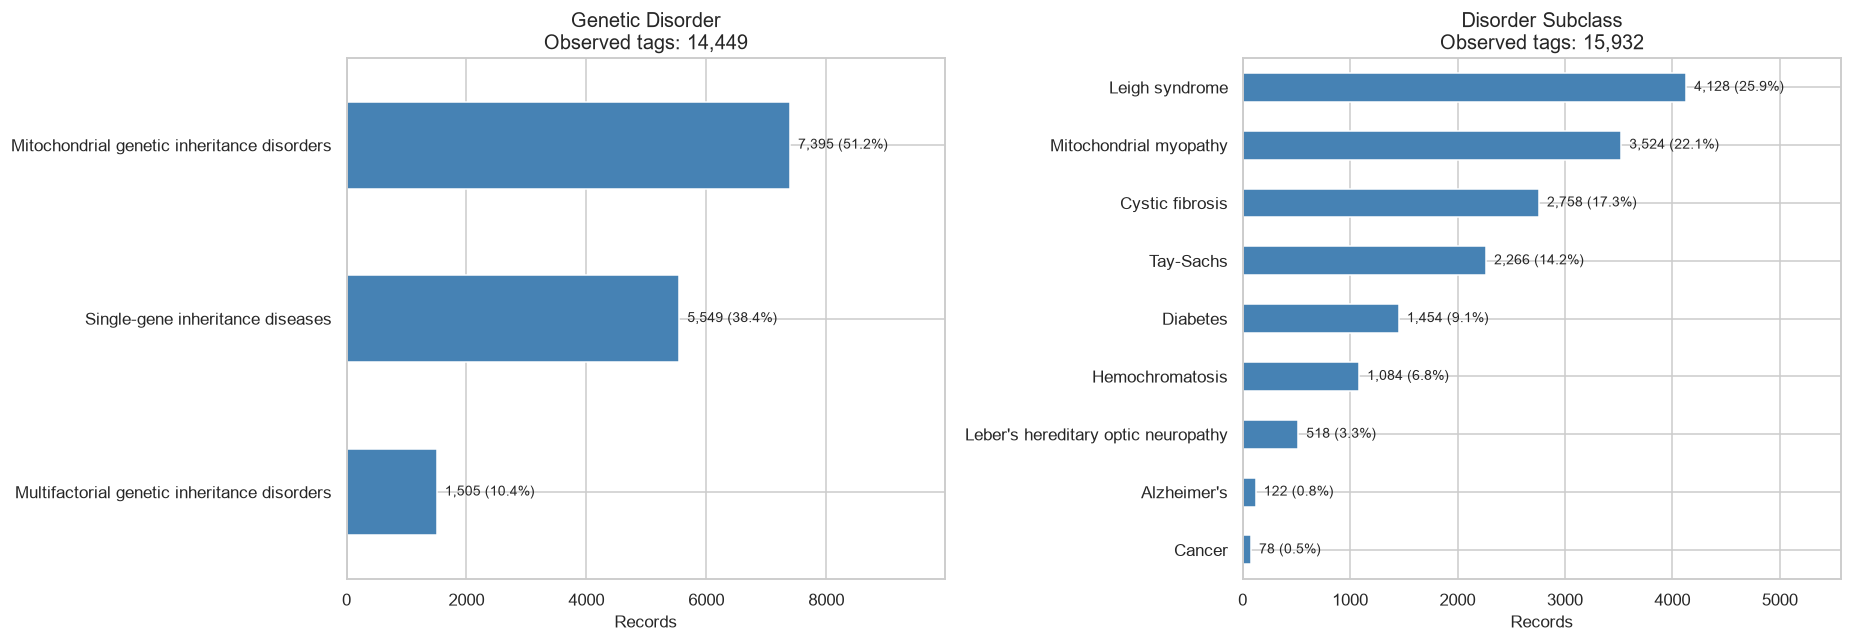

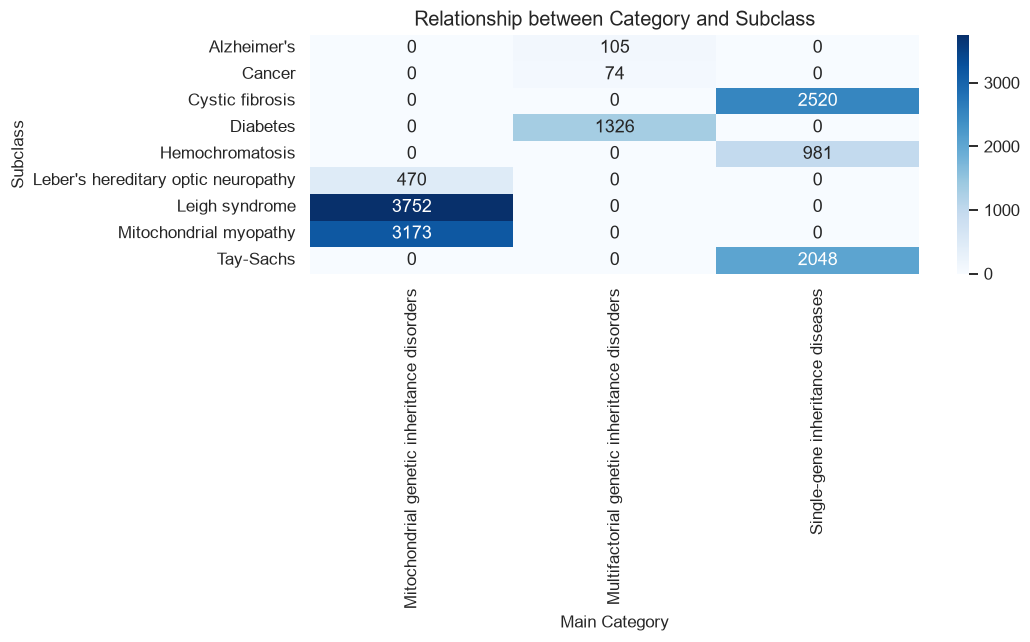

Main categories observed by subclass:


,n_categories
Disorder Subclass,
Alzheimer's,1
Cancer,1
Cystic fibrosis,1
Diabetes,1
Hemochromatosis,1
Leber's hereditary optic neuropathy,1
Leigh syndrome,1
Mitochondrial myopathy,1
Tay-Sachs,1


In [6]:
# =============================================================================
# EDA 3: CLASS BALANCE AND TARGET HIERARCHY
# =============================================================================

fig, axes = plt.subplots(1, 2, figsize=(17, 6))

for ax, target in zip(axes, TARGET_COLUMNS):
    counts = eda_train[target].value_counts()
    percentages = counts.div(counts.sum()).mul(100)

    display(pd.DataFrame({
        "n": counts,
        "percentage": percentages.round(2),
    }))

    ordered = counts.sort_values()
    ordered.plot.barh(ax=ax, color="steelblue")

    ax.set_title(f"{target}\nObserved tags: {counts.sum():,}")
    ax.set_xlabel("Records")
    ax.set_ylabel("")

    for position, (label, count) in enumerate(ordered.items()):
        ax.text(
            count, position,
            f"  {count:,} ({percentages[label]:.1f}%)",
            va="center", fontsize=9,
        )

    ax.set_xlim(0, counts.max() * 1.35)

plt.tight_layout()
plt.show()

hierarchy = pd.crosstab(
    eda_train["Disorder Subclass"],
    eda_train["Genetic Disorder"],
)

plt.figure(figsize=(10, 6))
sns.heatmap(hierarchy, annot=True, fmt="d", cmap="Blues")
plt.title("Relationship between Category and Subclass")
plt.xlabel("Main Category")
plt.ylabel("Subclass")
plt.tight_layout()
plt.show()

print("Main categories observed by subclass:")
display(hierarchy.gt(0).sum(axis=1).to_frame("n_categories"))

,Training,Test,percentage_point_difference
Heart Rate (rates/min,8.96,52.55,43.59
Respiratory Rate (breaths/min),9.25,52.73,43.49
Institute Name,21.91,52.87,30.96
Maternal gene,12.17,39.33,27.16
Test 1,9.19,22.40,13.21
Folic acid details (peri-conceptional),9.05,22.10,13.05
No. of previous abortion,9.12,22.14,13.02
History of anomalies in previous pregnancies,9.17,22.16,12.99
Follow-up,9.10,22.08,12.98
Test 3,9.23,22.18,12.94


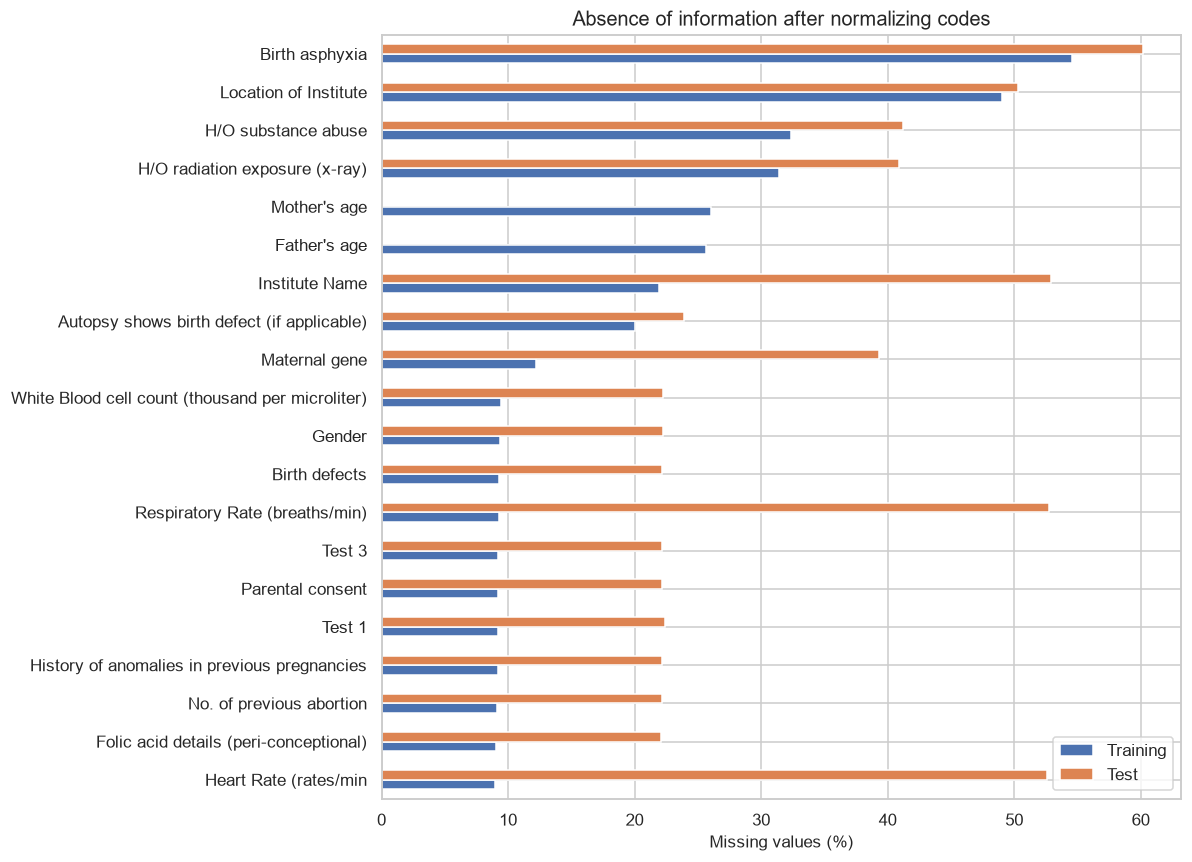

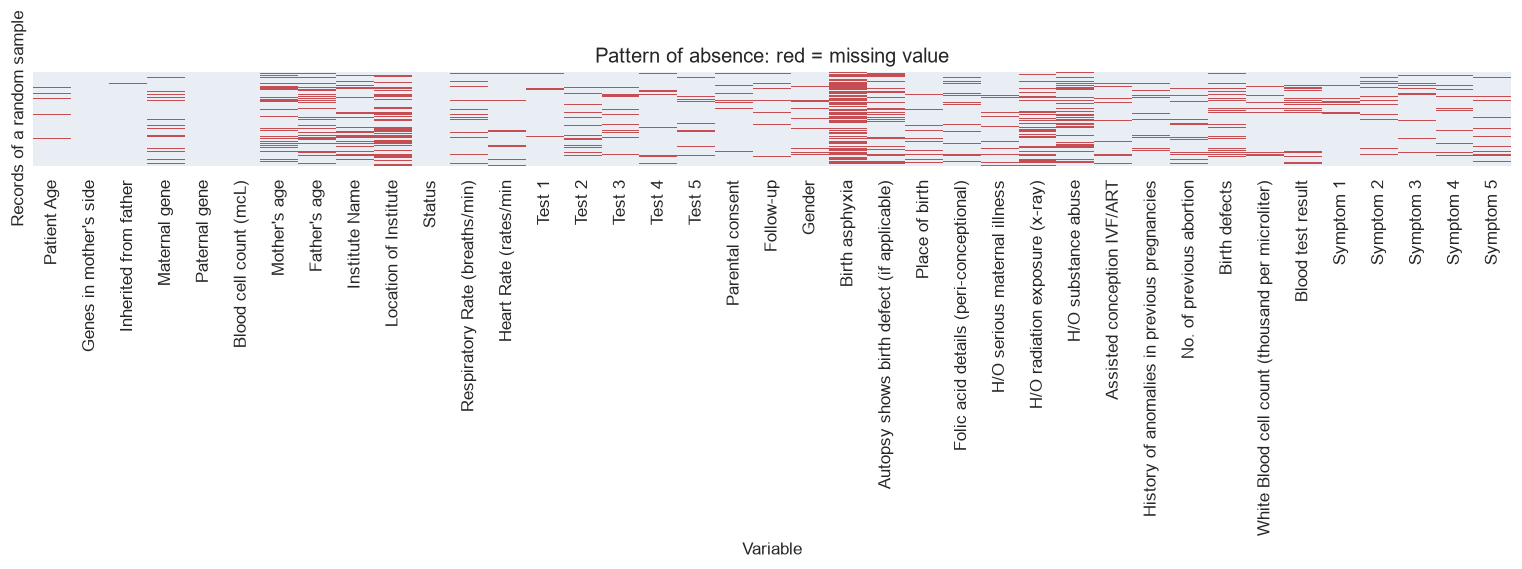

In [7]:
# =============================================================================
# EDA 4: MISSING DATA AND TRAIN–TEST DIFFERENCES
# =============================================================================

excluded_from_missing_plot = [
    "Patient Id", "Patient First Name",
    "Family Name", "Father's name",
]

feature_columns = [
    column for column in eda_test.columns
    if column not in excluded_from_missing_plot
]

missing_comparison = pd.DataFrame({
    "Training": (
        eda_train[feature_columns].isna().mean() * 100
    ),
    "Test": eda_test[feature_columns].isna().mean() * 100,
})

missing_comparison["percentage_point_difference"] = (
    missing_comparison["Test"]
    - missing_comparison["Training"]
)

display(
    missing_comparison
    .sort_values("percentage_point_difference", ascending=False)
    .round(2)
)

top_missing = (
    missing_comparison[["Training", "Test"]]
    .max(axis=1)
    .sort_values(ascending=False)
    .head(20)
    .index
)

missing_comparison.loc[
    top_missing, ["Training", "Test"]
].sort_values("Training").plot.barh(figsize=(11, 8))

plt.xlabel("Missing values (%)")
plt.title("Absence of information after normalizing codes")
plt.tight_layout()
plt.show()

missing_sample = eda_train[feature_columns].sample(
    n=min(300, len(eda_train)),
    random_state=EDA_SEED,
)

plt.figure(figsize=(14, 5))
sns.heatmap(
    missing_sample.isna(),
    cmap=["#e8eef3", "#c44e52"],
    cbar=False,
    yticklabels=False,
)
plt.title("Pattern of absence: red = missing value")
plt.xlabel("Variable")
plt.ylabel("Records of a random sample")
plt.tight_layout()
plt.show()

In [8]:
# =============================================================================
# EDA 5: SENSITIVITY TO COMPLETE-CASE DELETION
# =============================================================================

# Excluir identificadores, nombres e instituto para esta comparación.
analysis_columns = [
    column for column in eda_train.columns
    if column not in [
        "Patient Id", "Patient First Name",
        "Family Name", "Father's name",
        "Institute Name", "Location of Institute",
    ]
]

complete_cases = eda_train.dropna(subset=analysis_columns)

retention = pd.DataFrame({
    "strategy": [
        "Target label available",
        "Additionally, all analyzed fields are complete",
    ],
    "records": [len(eda_train), len(complete_cases)],
    "target_classes": [
        eda_train[EDA_TARGET].nunique(),
        complete_cases[EDA_TARGET].nunique(),
    ],
})

retention["retenido_%"] = (
    retention["records"] / len(eda_train) * 100
)

display(retention.round(2))

status_comparison = pd.DataFrame({
    "before": eda_train["Status"].value_counts(normalize=True),
    "complete_cases": complete_cases["Status"].value_counts(
        normalize=True
    ),
}).mul(100)

display(status_comparison.round(2))

print(
    "This comparison retains 'Not applicable' as a category.; "
    "It does not reproduce its conversion into a shortage."
)

,strategy,records,target_classes,retenido_%
0,Target label available,15932,9,100.00
1,"Additionally, all analyzed fields are complete",1278,9,8.02


,before,complete_cases
Status,,
Alive,50.45,60.41
Deceased,49.55,39.59


This comparison retains 'Not applicable' as a category.; It does not reproduce its conversion into a shortage.


,count,mean,std,min,1%,25%,50%,75%,99%,max
Patient Age,14938.0,6.952,4.319,0.000,0.000,3.000,7.000,11.000,14.000,14.000
Mother's age,11780.0,34.582,9.824,18.000,18.000,26.000,35.000,43.000,51.000,51.000
Father's age,11851.0,41.971,13.105,20.000,20.000,30.000,42.000,53.000,64.000,64.000
Blood cell count (mcL),15932.0,4.899,0.199,4.093,4.443,4.763,4.899,5.033,5.365,5.592
White Blood cell count (thousand per microliter),14423.0,7.488,2.656,3.000,3.000,5.426,7.485,9.531,12.000,12.000
No. of previous abortion,14479.0,2.005,1.407,0.000,0.000,1.000,2.000,3.000,4.000,4.000


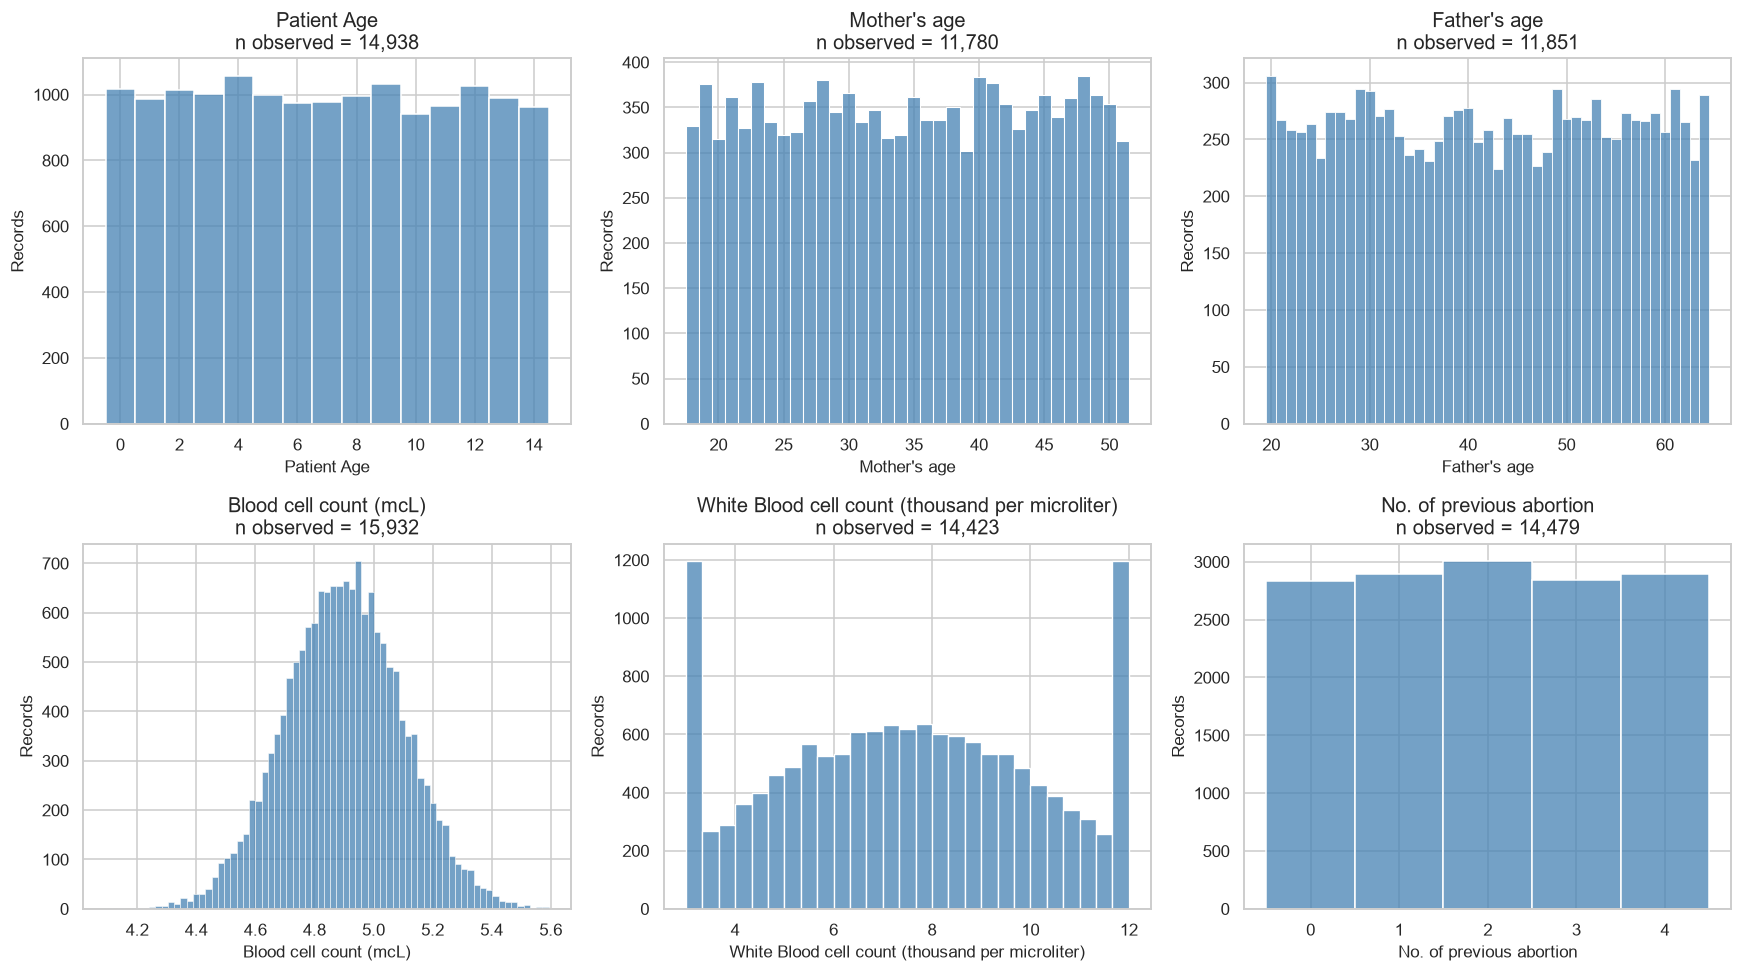

,,lower_limit_IQR,upper_limit_IQR,outside_limits_n,n_observed
0,Patient Age,-9.000,23.000,0,14938
1,Mother's age,0.500,68.500,0,11780
2,Father's age,-4.500,87.500,0,11851
3,Blood cell count (mcL),4.359,5.437,112,15932
4,White Blood cell count (thousand per microliter),-0.732,15.688,0,14423
5,No. of previous abortion,-2.000,6.000,0,14479


In [9]:
# =============================================================================
# EDA 6: NUMERIC DISTRIBUTIONS AND EXTREME VALUES
# =============================================================================

display(
    eda_train[NUMERIC_EDA_COLUMNS]
    .describe(percentiles=[0.01, 0.25, 0.50, 0.75, 0.99])
    .T
    .round(3)
)

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, column in zip(axes.flat, NUMERIC_EDA_COLUMNS):
    values = eda_train[column].dropna()
    discrete = column in [
        "Patient Age", "Mother's age", "Father's age",
        "No. of previous abortion",
    ]

    sns.histplot(
        x=values,
        discrete=discrete,
        kde=False,
        ax=ax,
        color="steelblue",
    )
    ax.set_title(f"{column}\nn observed = {len(values):,}")
    ax.set_ylabel("Records")

plt.tight_layout()
plt.show()

extreme_summary = []

for column in NUMERIC_EDA_COLUMNS:
    values = eda_train[column].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr

    extreme_summary.append({
        "": column,
        "lower_limit_IQR": lower,
        "upper_limit_IQR": upper,
        "outside_limits_n": ((values < lower) | (values > upper)).sum(),
        "n_observed": len(values),
    })

display(pd.DataFrame(extreme_summary).round(3))


Variable: Patient Age


,n,mediana,q25,q75
Disorder Subclass,,,,
Leigh syndrome,3868,7.0,3.00,11.0
Mitochondrial myopathy,3316,7.0,3.00,11.0
Cystic fibrosis,2589,7.0,3.00,11.0
Tay-Sachs,2125,7.0,3.00,11.0
Diabetes,1349,7.0,3.00,11.0
Hemochromatosis,1016,7.0,3.00,11.0
Leber's hereditary optic neuropathy,484,7.0,3.00,10.0
Alzheimer's,118,6.0,3.25,10.0
Cancer,73,8.0,4.00,12.0


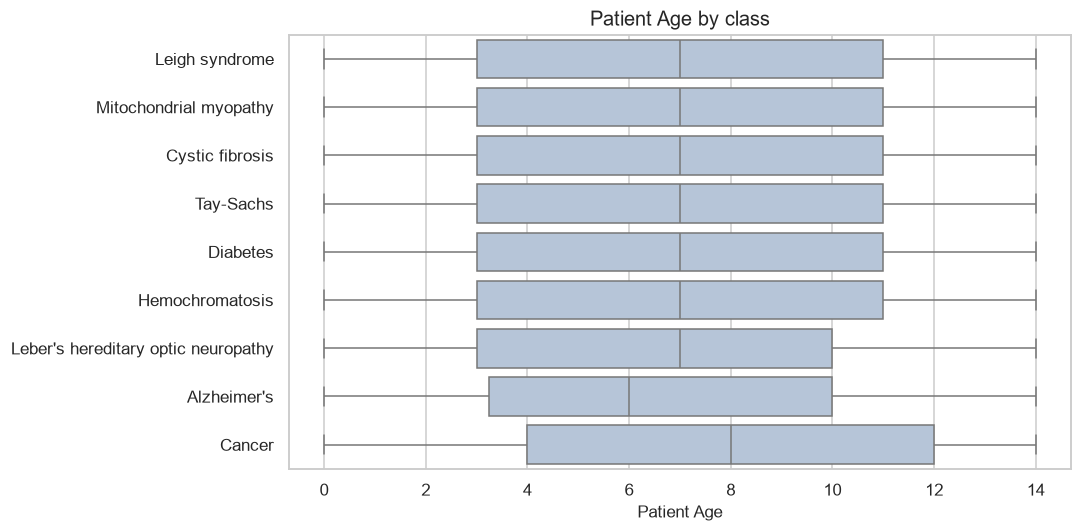


Variable: Mother's age


,n,mediana,q25,q75
Disorder Subclass,,,,
Leigh syndrome,3020,35.0,26.0,43.00
Mitochondrial myopathy,2595,35.0,26.0,43.00
Cystic fibrosis,2066,35.0,26.0,43.00
Tay-Sachs,1690,34.0,26.0,43.00
Diabetes,1087,35.0,26.0,43.00
Hemochromatosis,799,35.0,27.0,43.00
Leber's hereditary optic neuropathy,378,36.0,28.0,44.75
Alzheimer's,85,35.0,27.0,43.00
Cancer,60,34.5,25.0,42.00


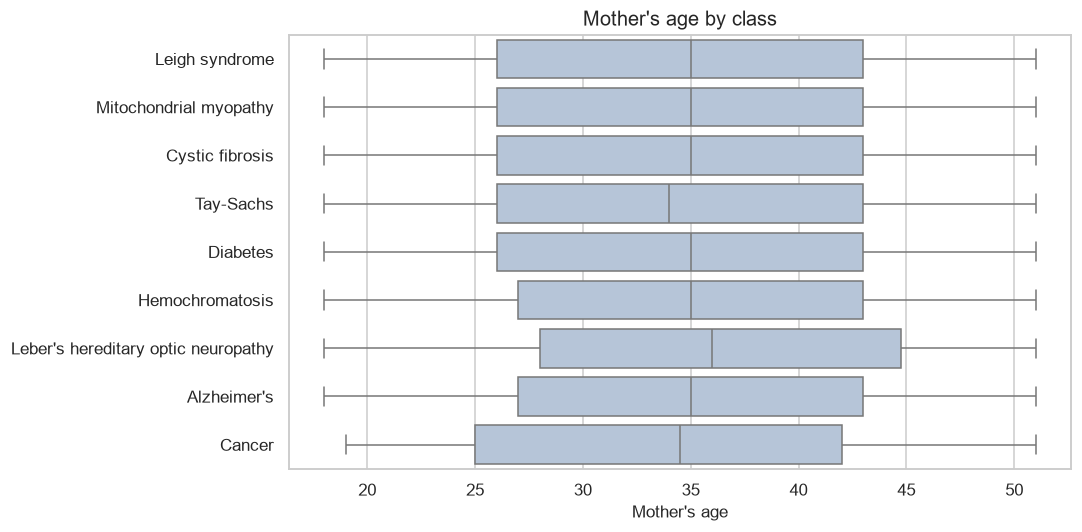


Variable: Father's age


,n,mediana,q25,q75
Disorder Subclass,,,,
Leigh syndrome,3026,41.0,30.00,53.00
Mitochondrial myopathy,2639,42.0,30.00,53.00
Cystic fibrosis,2052,42.0,31.00,53.00
Tay-Sachs,1689,42.0,31.00,53.00
Diabetes,1090,42.0,31.00,54.00
Hemochromatosis,820,43.0,31.00,54.00
Leber's hereditary optic neuropathy,390,41.0,31.00,55.00
Alzheimer's,89,44.0,32.00,56.00
Cancer,56,37.5,26.75,53.75


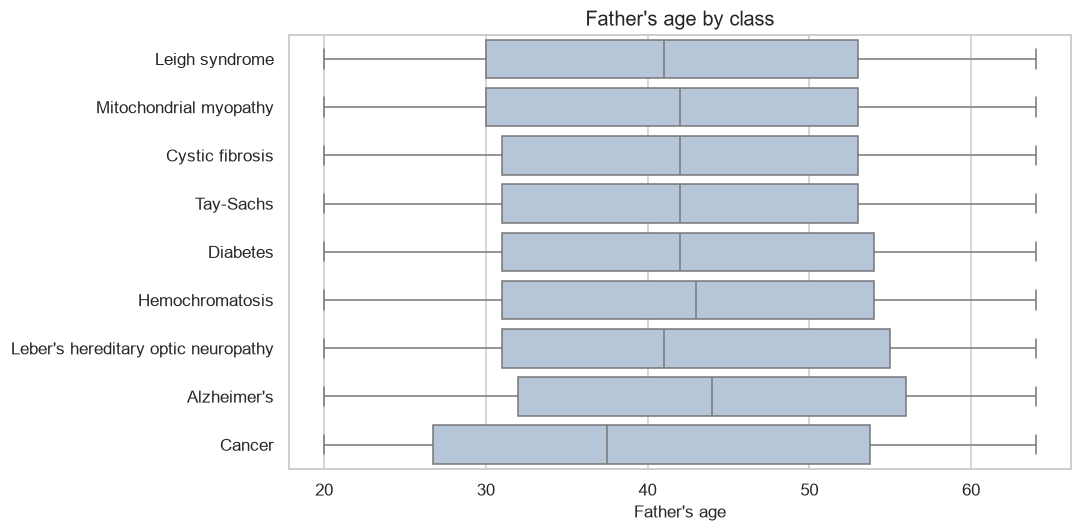


Variable: Blood cell count (mcL)


,n,mediana,q25,q75
Disorder Subclass,,,,
Leigh syndrome,4128,4.905,4.767,5.041
Mitochondrial myopathy,3524,4.897,4.759,5.026
Cystic fibrosis,2758,4.901,4.768,5.030
Tay-Sachs,2266,4.896,4.765,5.035
Diabetes,1454,4.891,4.764,5.038
Hemochromatosis,1084,4.893,4.752,5.023
Leber's hereditary optic neuropathy,518,4.899,4.772,5.036
Alzheimer's,122,4.920,4.732,5.036
Cancer,78,4.875,4.725,4.955


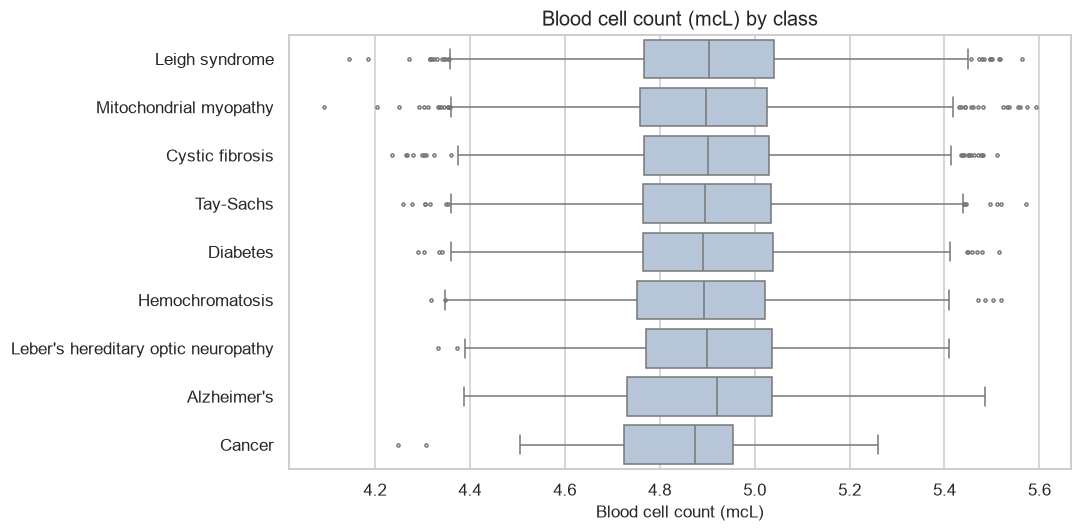


Variable: White Blood cell count (thousand per microliter)


,n,mediana,q25,q75
Disorder Subclass,,,,
Leigh syndrome,3718,7.460,5.420,9.467
Mitochondrial myopathy,3206,7.508,5.431,9.555
Cystic fibrosis,2482,7.485,5.525,9.537
Tay-Sachs,2068,7.496,5.398,9.429
Diabetes,1320,7.417,5.261,9.685
Hemochromatosis,971,7.490,5.329,9.504
Leber's hereditary optic neuropathy,476,7.684,5.585,9.747
Alzheimer's,109,7.624,4.956,10.072
Cancer,73,7.564,6.133,10.257


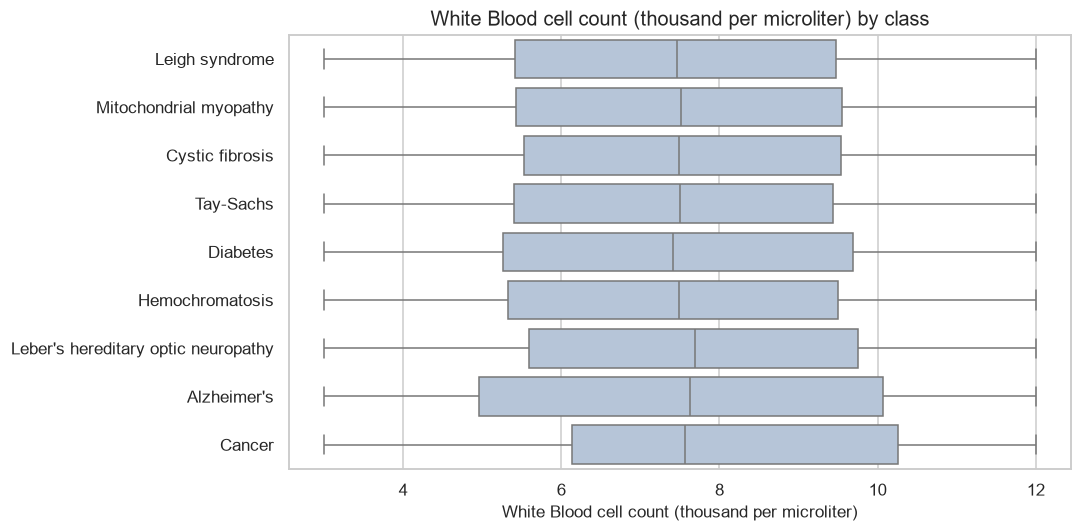


Variable: No. of previous abortion


,n,mediana,q25,q75
Disorder Subclass,,,,
Leigh syndrome,3746,2.0,1.0,3.0
Mitochondrial myopathy,3207,2.0,1.0,3.0
Cystic fibrosis,2524,2.0,1.0,3.0
Tay-Sachs,2058,2.0,1.0,3.0
Diabetes,1325,2.0,1.0,3.0
Hemochromatosis,963,2.0,1.0,3.0
Leber's hereditary optic neuropathy,472,2.0,1.0,3.0
Alzheimer's,115,2.0,1.0,3.0
Cancer,69,2.0,1.0,3.0


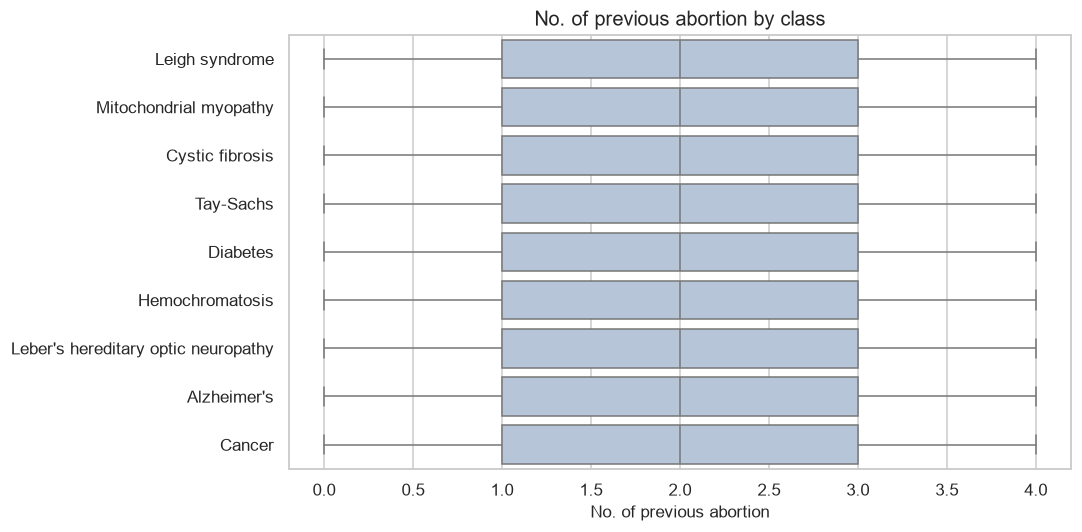

In [10]:
# =============================================================================
# EDA 7: NUMERIC VARIABLES BY TARGET CLASS
# =============================================================================

class_order = eda_train[EDA_TARGET].value_counts().index.tolist()

for column in NUMERIC_EDA_COLUMNS:
    summary = (
        eda_train.groupby(EDA_TARGET)[column]
        .agg(
            n="count",
            mediana="median",
            q25=lambda values: values.quantile(0.25),
            q75=lambda values: values.quantile(0.75),
        )
        .reindex(class_order)
    )

    print(f"\nVariable: {column}")
    display(summary.round(3))

    plt.figure(figsize=(10, 5))
    sns.boxplot(
        data=eda_train,
        x=column,
        y=EDA_TARGET,
        order=class_order,
        color="lightsteelblue",
        showfliers=True,
        fliersize=2,
    )
    plt.title(f"{column} by class")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()

,variable,categorias
0,Genes in mother's side,"[No, Yes]"
1,Inherited from father,"[Yes, No]"
2,Maternal gene,"[No, Yes]"
3,Paternal gene,"[No, Yes]"
4,Gender,"[Female, Ambiguous, Male]"
5,Birth asphyxia,"[No, Yes]"
6,Folic acid details (peri-conceptional),"[No, Yes]"
7,H/O serious maternal illness,"[No, Yes]"
8,H/O radiation exposure (x-ray),"[No, Yes, Not applicable]"
9,H/O substance abuse,"[Yes, No, Not applicable]"


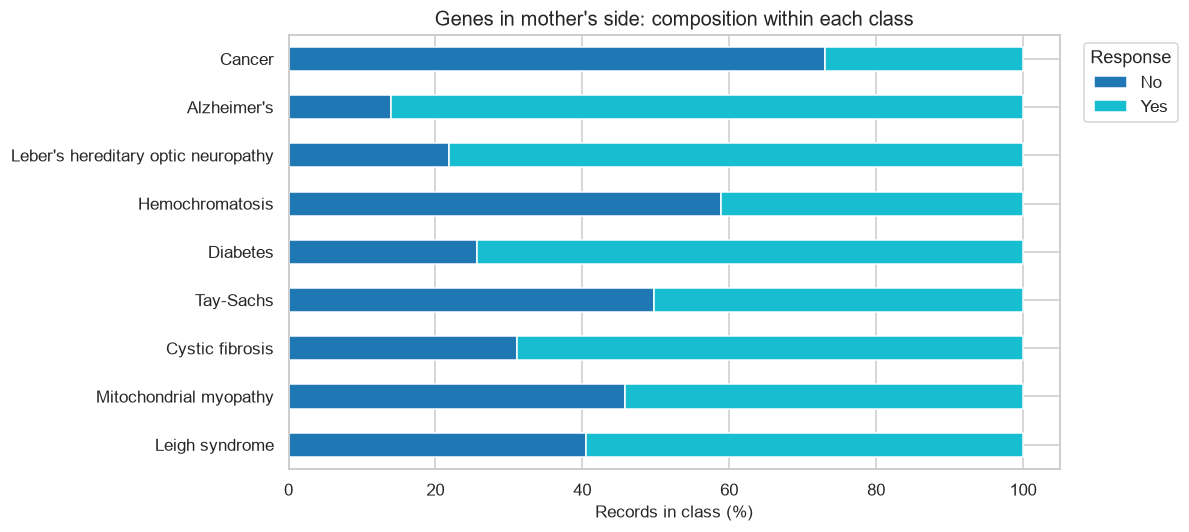

Genes in mother's side,No,Yes
Disorder Subclass,,
Leigh syndrome,1670,2458
Mitochondrial myopathy,1616,1908
Cystic fibrosis,858,1900
Tay-Sachs,1126,1140
Diabetes,373,1081
Hemochromatosis,638,446
Leber's hereditary optic neuropathy,113,405
Alzheimer's,17,105
Cancer,57,21


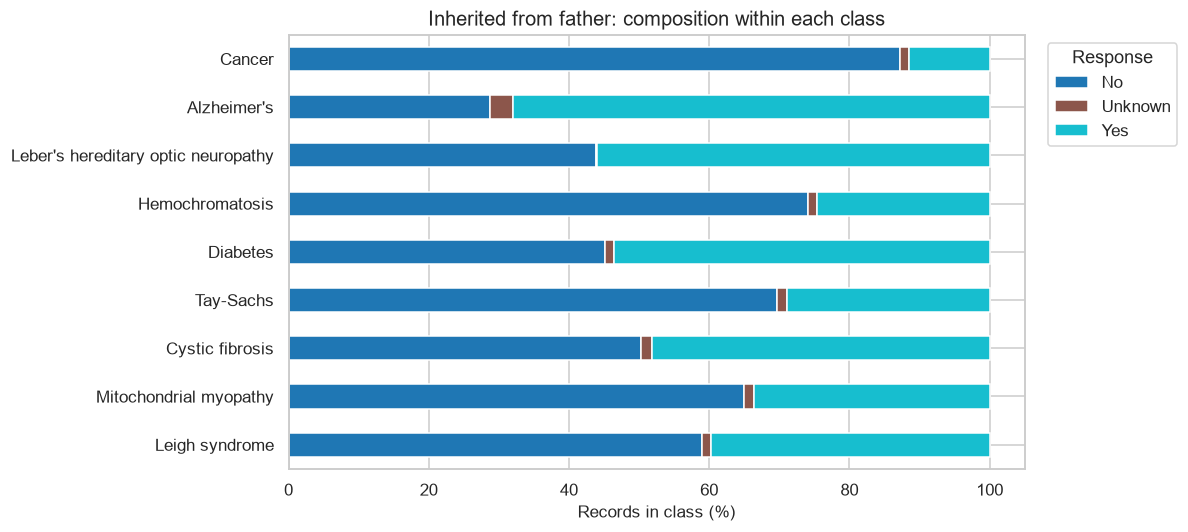

Inherited from father,No,Unknown,Yes
Disorder Subclass,,,
Leigh syndrome,2437,49,1642
Mitochondrial myopathy,2289,52,1183
Cystic fibrosis,1388,40,1330
Tay-Sachs,1580,31,655
Diabetes,656,19,779
Hemochromatosis,803,14,267
Leber's hereditary optic neuropathy,227,1,290
Alzheimer's,35,4,83
Cancer,68,1,9


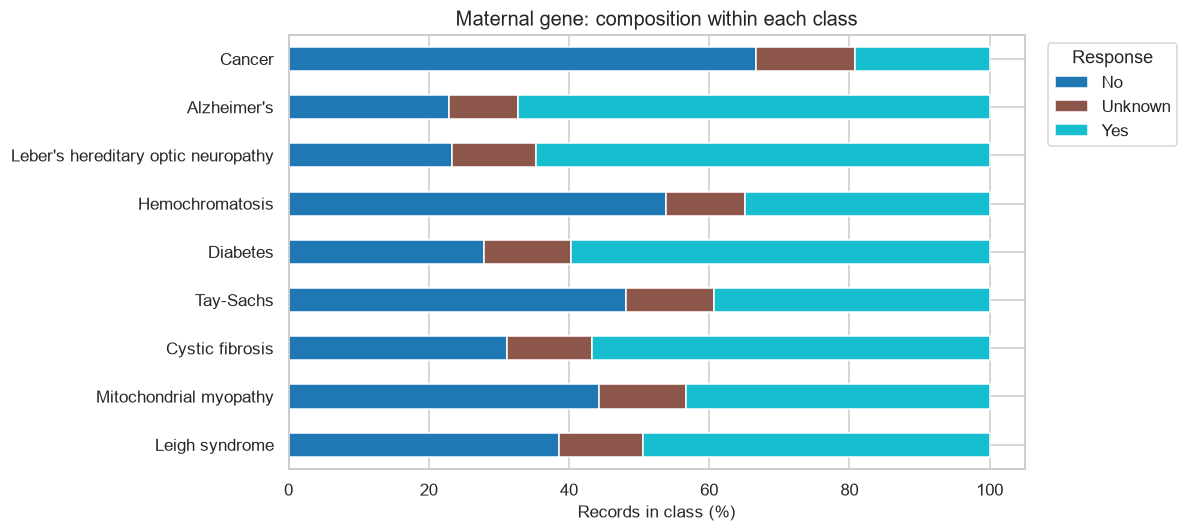

Maternal gene,No,Unknown,Yes
Disorder Subclass,,,
Leigh syndrome,1594,493,2041
Mitochondrial myopathy,1558,440,1526
Cystic fibrosis,858,335,1565
Tay-Sachs,1091,283,892
Diabetes,405,180,869
Hemochromatosis,583,123,378
Leber's hereditary optic neuropathy,121,62,335
Alzheimer's,28,12,82
Cancer,52,11,15


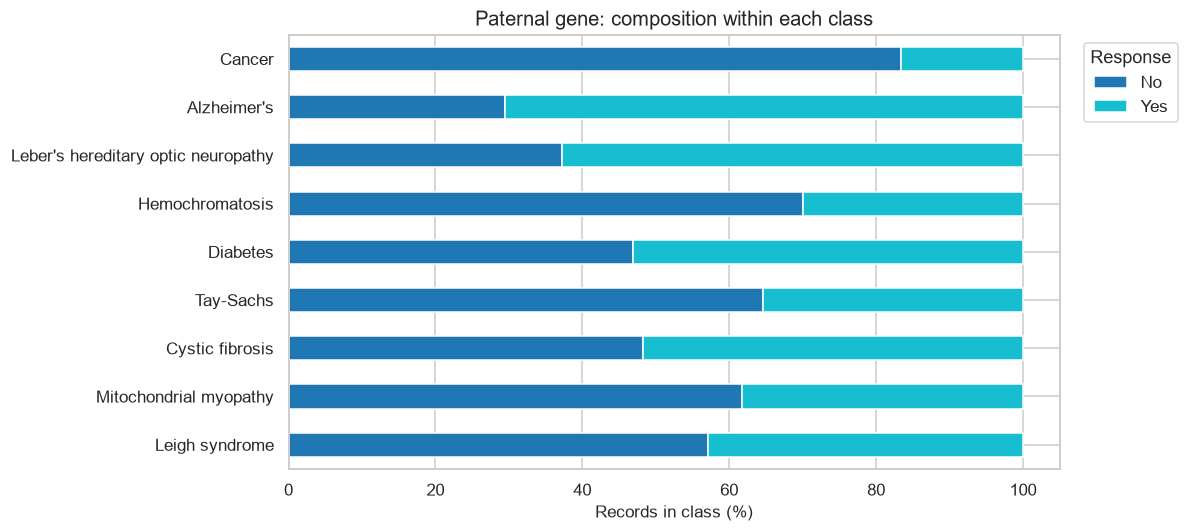

Paternal gene,No,Yes
Disorder Subclass,,
Leigh syndrome,2357,1771
Mitochondrial myopathy,2176,1348
Cystic fibrosis,1332,1426
Tay-Sachs,1464,802
Diabetes,682,772
Hemochromatosis,759,325
Leber's hereditary optic neuropathy,193,325
Alzheimer's,36,86
Cancer,65,13


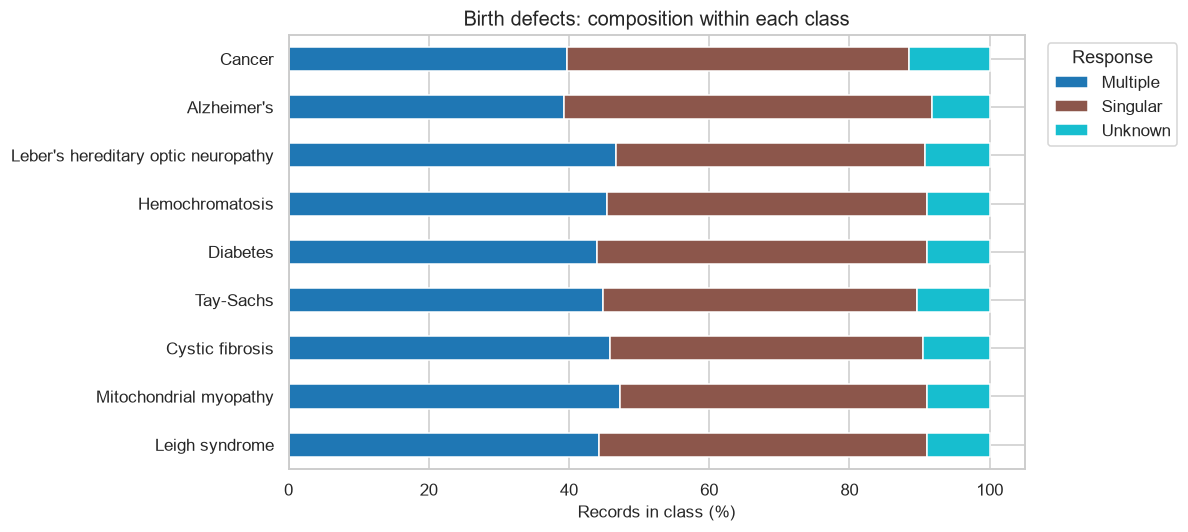

Birth defects,Multiple,Singular,Unknown
Disorder Subclass,,,
Leigh syndrome,1826,1933,369
Mitochondrial myopathy,1666,1542,316
Cystic fibrosis,1264,1231,263
Tay-Sachs,1016,1015,235
Diabetes,640,684,130
Hemochromatosis,492,495,97
Leber's hereditary optic neuropathy,242,228,48
Alzheimer's,48,64,10
Cancer,31,38,9


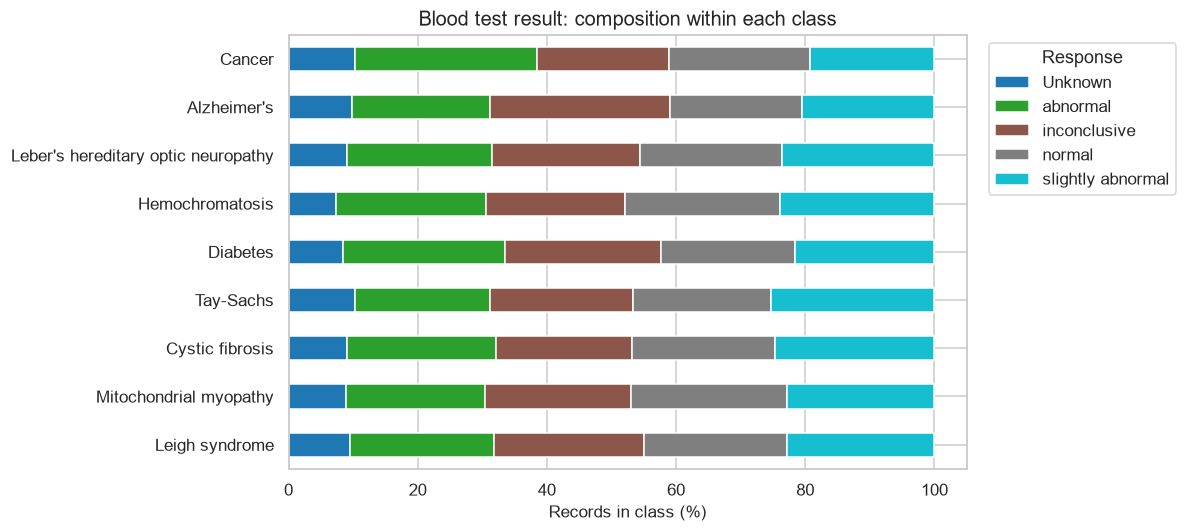

Blood test result,Unknown,abnormal,inconclusive,normal,slightly abnormal
Disorder Subclass,,,,,
Leigh syndrome,394,921,957,916,940
Mitochondrial myopathy,313,760,794,853,804
Cystic fibrosis,250,634,583,609,682
Tay-Sachs,233,473,503,485,572
Diabetes,123,364,352,302,313
Hemochromatosis,80,251,234,259,260
Leber's hereditary optic neuropathy,47,116,119,114,122
Alzheimer's,12,26,34,25,25
Cancer,8,22,16,17,15


In [11]:
# =============================================================================
# EDA 8: CATEGORICAL FEATURES BY TARGET CLASS
# =============================================================================

CATEGORICAL_EDA_COLUMNS = FAMILY_COLUMNS + [
    "Gender",
    "Birth asphyxia",
    "Folic acid details (peri-conceptional)",
    "H/O serious maternal illness",
    "H/O radiation exposure (x-ray)",
    "H/O substance abuse",
    "Assisted conception IVF/ART",
    "History of anomalies in previous pregnancies",
    "Birth defects",
    "Blood test result",
]

# Mostrar todos los valores originales observados antes de codificar.
category_audit = pd.DataFrame({
    "variable": CATEGORICAL_EDA_COLUMNS,
    "categorias": [
        eda_train[column].dropna().unique().tolist()
        for column in CATEGORICAL_EDA_COLUMNS
    ],
})
display(category_audit)

# Primer conjunto de figuras; puedes modificar esta selección.
CATEGORICAL_TO_PLOT = FAMILY_COLUMNS + [
    "Birth defects",
    "Blood test result",
]

for column in CATEGORICAL_TO_PLOT:
    categories = eda_train[column].fillna("Unknown")

    counts = pd.crosstab(
        eda_train[EDA_TARGET],
        categories,
    ).reindex(class_order, fill_value=0)

    proportions = counts.div(counts.sum(axis=1), axis=0).mul(100)

    ax = proportions.plot.barh(
        stacked=True,
        figsize=(11, 5),
        colormap="tab10",
    )
    ax.set_title(f"{column}: composition within each class")
    ax.set_xlabel("Records in class (%)")
    ax.set_ylabel("")
    ax.legend(title="Response", bbox_to_anchor=(1.02, 1))
    plt.tight_layout()
    plt.show()

    display(counts)

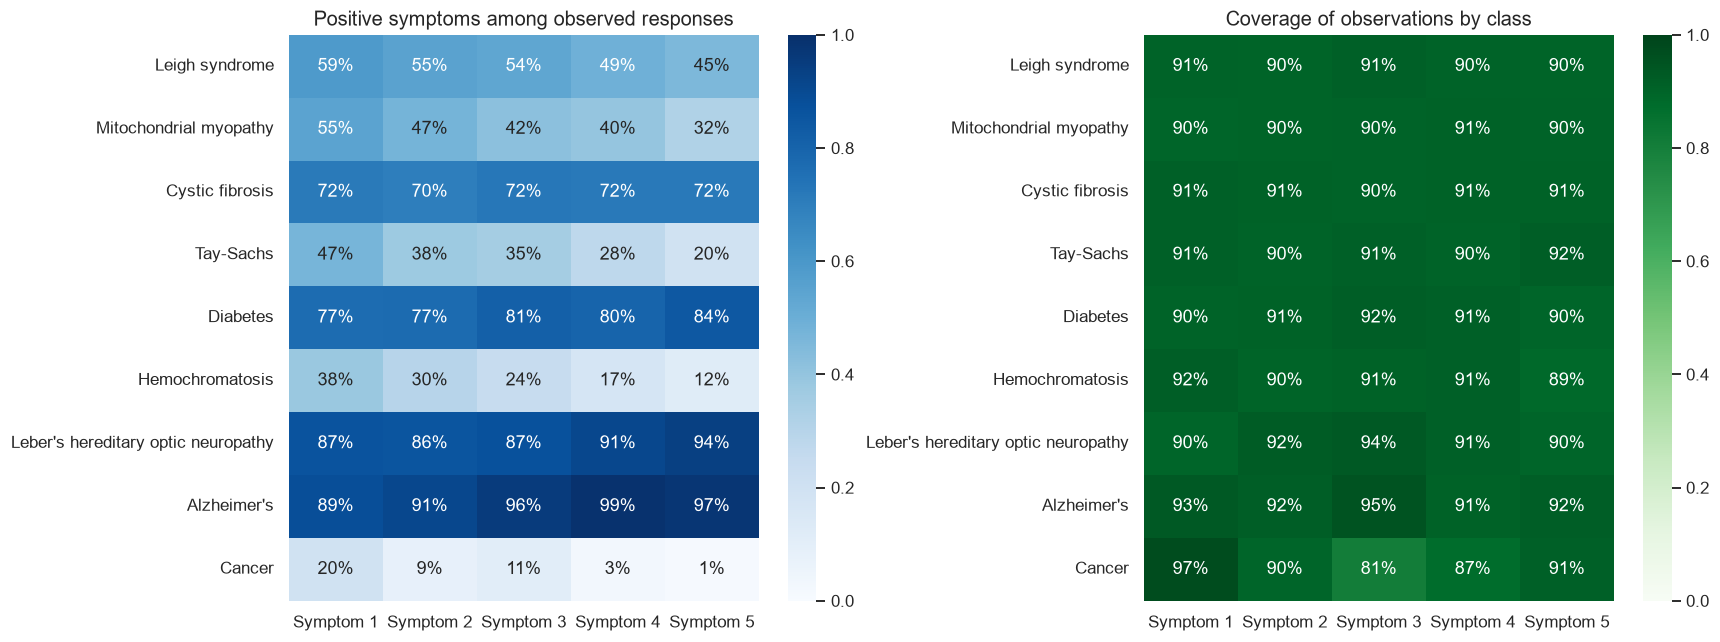

Number of observations by symptom and class:


,Symptom 1,Symptom 2,Symptom 3,Symptom 4,Symptom 5
Disorder Subclass,,,,,
Leigh syndrome,3737,3718,3764,3730,3720
Mitochondrial myopathy,3166,3170,3187,3205,3188
Cystic fibrosis,2516,2506,2493,2507,2508
Tay-Sachs,2063,2045,2067,2050,2086
Diabetes,1315,1321,1339,1325,1304
Hemochromatosis,998,974,985,989,960
Leber's hereditary optic neuropathy,464,479,485,472,464
Alzheimer's,114,112,116,111,112
Cancer,76,70,63,68,71


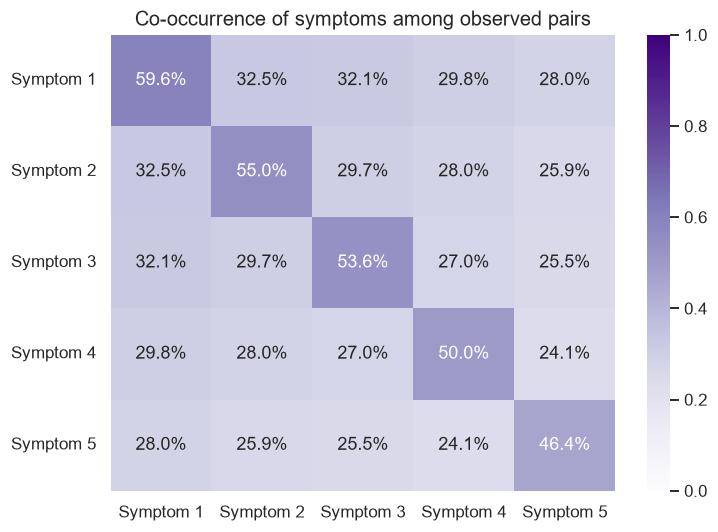

Number of records that support each pair:


,Symptom 1,Symptom 2,Symptom 3,Symptom 4,Symptom 5
Symptom 1,14449,13148,13205,13169,13130
Symptom 2,13148,14395,13161,13117,13107
Symptom 3,13205,13161,14499,13214,13163
Symptom 4,13169,13117,13214,14457,13154
Symptom 5,13130,13107,13163,13154,14413


In [12]:
# =============================================================================
# EDA 9: SYMPTOMS — PREVALENCE, COVERAGE AND COOCCURRENCE
# =============================================================================

grouped_symptoms = eda_train.groupby(EDA_TARGET)[SYMPTOM_COLUMNS]

symptom_prevalence = grouped_symptoms.mean().reindex(class_order)
symptom_observed = grouped_symptoms.count().reindex(class_order)

class_sizes = (
    eda_train.groupby(EDA_TARGET).size().reindex(class_order)
)

symptom_coverage = symptom_observed.div(class_sizes, axis=0)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(
    symptom_prevalence,
    annot=True, fmt=".0%",
    vmin=0, vmax=1,
    cmap="Blues",
    ax=axes[0],
)
axes[0].set_title("Positive symptoms among observed responses")

sns.heatmap(
    symptom_coverage,
    annot=True, fmt=".0%",
    vmin=0, vmax=1,
    cmap="Greens",
    ax=axes[1],
)
axes[1].set_title("Coverage of observations by class")

for ax in axes:
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

print("Number of observations by symptom and class:")
display(symptom_observed)

# Proportion with both positive symptoms,
# conditioned on both being observed.
cooccurrence = pd.DataFrame(
    np.nan, index=SYMPTOM_COLUMNS, columns=SYMPTOM_COLUMNS
)
pair_support = cooccurrence.copy()

for first in SYMPTOM_COLUMNS:
    for second in SYMPTOM_COLUMNS:
        observed = (
            eda_train[first].notna()
            & eda_train[second].notna()
        )
        pair_support.loc[first, second] = observed.sum()

        if observed.any():
            cooccurrence.loc[first, second] = (
                eda_train.loc[observed, first].eq(1)
                & eda_train.loc[observed, second].eq(1)
            ).mean()

plt.figure(figsize=(7, 5))
sns.heatmap(
    cooccurrence,
    annot=True, fmt=".1%",
    vmin=0, vmax=1,
    cmap="Purples",
)
plt.title("Co-occurrence of symptoms among observed pairs")
plt.tight_layout()
plt.show()

print("Number of records that support each pair:")
display(pair_support.astype(int))

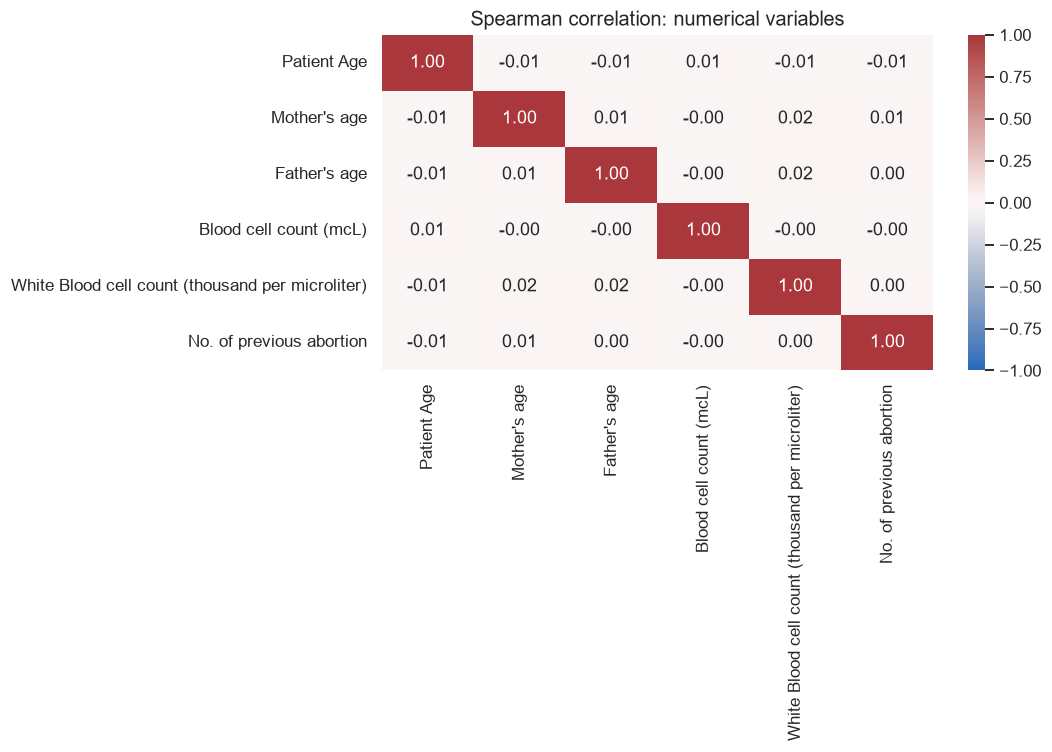

,variable,V_Cramer,observed_pairs
0,Genes in mother's side,0.201,15932
1,Inherited from father,0.194,15721
2,Maternal gene,0.188,13993
3,Paternal gene,0.166,15932
12,Birth defects,0.019,14455
13,Blood test result,0.016,14472
4,Gender,0.016,14442
11,History of anomalies in previous pregnancies,0.011,14471
5,Birth asphyxia,0.000,7240
6,Folic acid details (peri-conceptional),0.000,14490


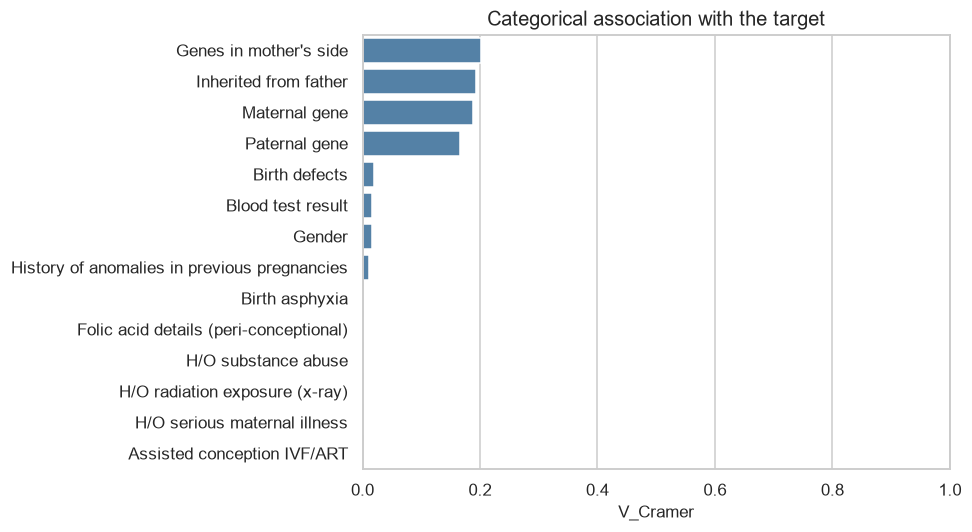

In [13]:
# =============================================================================
# EDA 10: ASSOCIATIONS AND REDUNDANCY
# =============================================================================

numeric_corr = eda_train[NUMERIC_EDA_COLUMNS].corr(
    method="spearman",
    min_periods=30,
)

plt.figure(figsize=(10, 7))
sns.heatmap(
    numeric_corr,
    annot=True, fmt=".2f",
    vmin=-1, vmax=1, center=0,
    cmap="vlag",
)
plt.title("Spearman correlation: numerical variables")
plt.tight_layout()
plt.show()


def corrected_cramers_v(first, second):
    """Bias-corrected Cramér's V; uses observed pairs."""
    paired = pd.DataFrame({"a": first, "b": second}).dropna()
    table = pd.crosstab(paired["a"], paired["b"])
    n = table.to_numpy().sum()

    if n <= 1 or min(table.shape) < 2:
        return np.nan, int(n)

    chi2 = chi2_contingency(table, correction=False)[0]
    rows, columns = table.shape

    phi2 = chi2 / n
    phi2_corrected = max(
        0, phi2 - ((columns - 1) * (rows - 1)) / (n - 1)
    )
    rows_corrected = rows - ((rows - 1)**2) / (n - 1)
    columns_corrected = columns - ((columns - 1)**2) / (n - 1)

    denominator = min(
        rows_corrected - 1,
        columns_corrected - 1,
    )

    if denominator <= 0:
        return np.nan, int(n)

    return np.sqrt(phi2_corrected / denominator), int(n)


association_rows = []

for column in CATEGORICAL_EDA_COLUMNS:
    association, n = corrected_cramers_v(
        eda_train[column],
        eda_train[EDA_TARGET],
    )
    association_rows.append({
        "variable": column,
        "V_Cramer": association,
        "observed_pairs": n,
    })

categorical_associations = (
    pd.DataFrame(association_rows)
    .sort_values("V_Cramer", ascending=False)
)

display(categorical_associations.round(3))

sns.barplot(
    data=categorical_associations,
    x="V_Cramer",
    y="variable",
    color="steelblue",
)
plt.xlim(0, 1)
plt.title("Categorical association with the target")
plt.ylabel("")
plt.tight_layout()
plt.show()

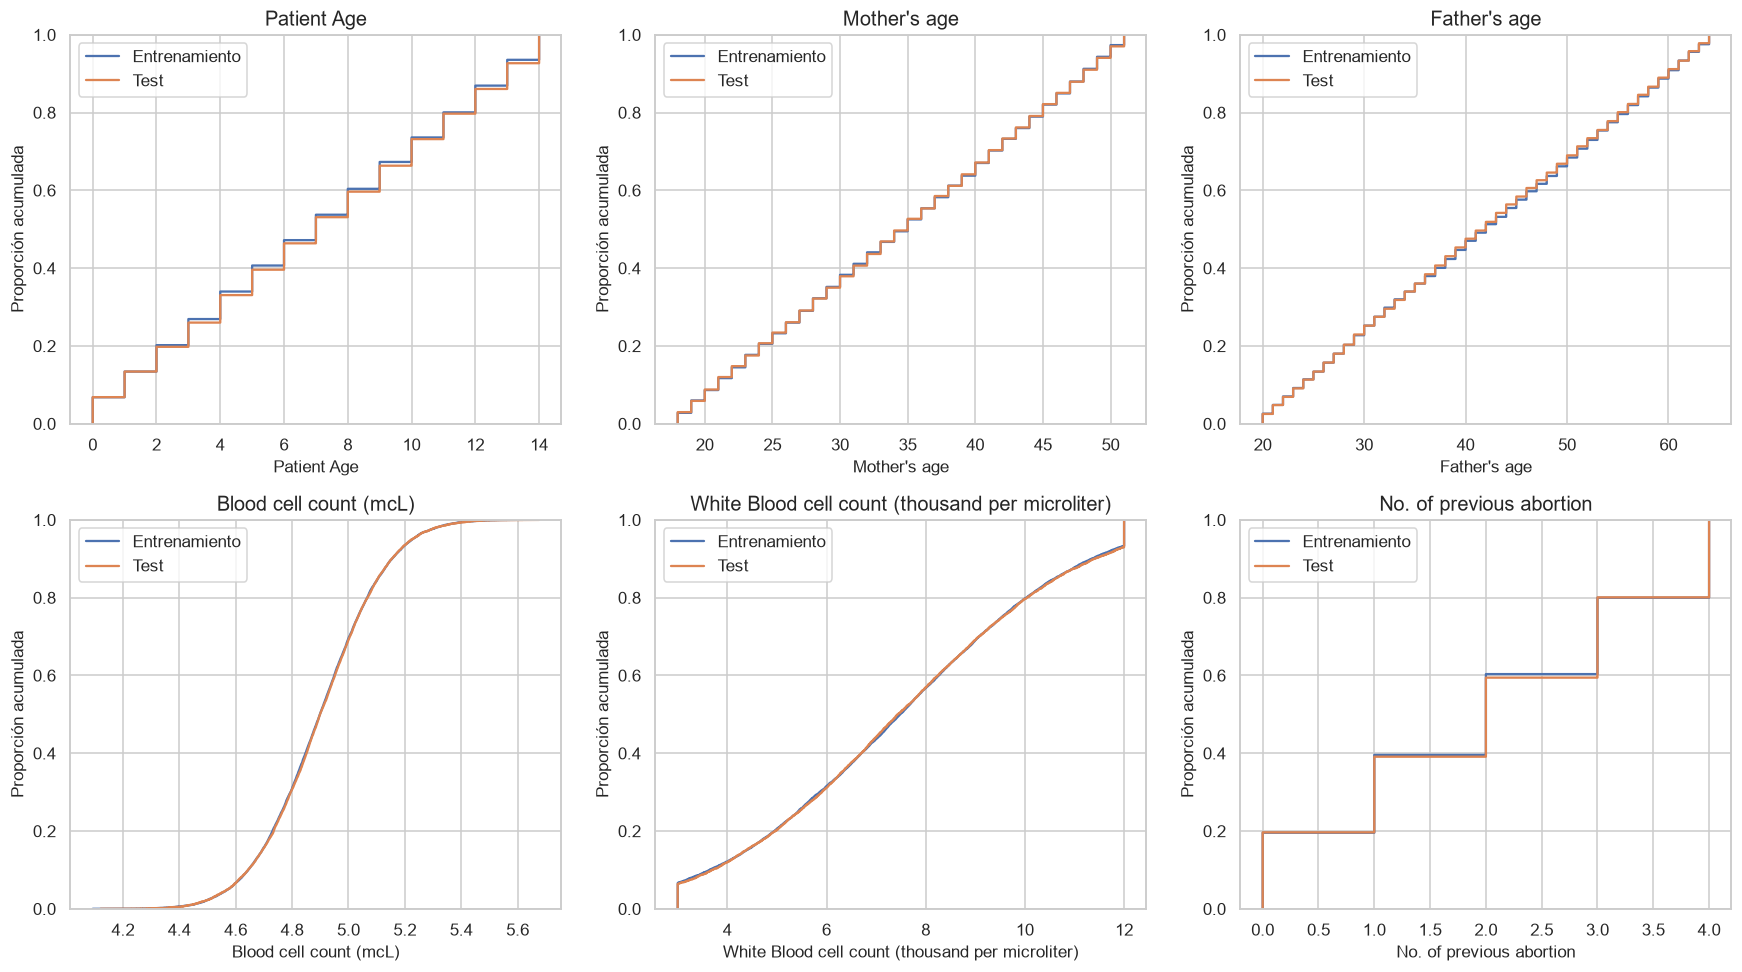

,variable,n_train,n_test,estadistico_KS
0,Patient Age,14938,9465,0.011
3,Blood cell count (mcL),15932,9465,0.010
2,Father's age,11851,9465,0.010
5,No. of previous abortion,14479,7369,0.009
4,White Blood cell count (thousand per microliter),14423,7363,0.008
1,Mother's age,11780,9465,0.005


,variable,new_test_categories


The KS statistic describes differences in observed distributionsit does not, on its own, establish their cause or predictive impact.


In [14]:
# =============================================================================
# EDA 11: TRAIN–TEST DISTRIBUTION COMPARISON
# =============================================================================

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
shift_rows = []

for ax, column in zip(axes.flat, NUMERIC_EDA_COLUMNS):
    train_values = eda_train[column].dropna()
    test_values = eda_test[column].dropna()

    sns.ecdfplot(x=train_values, ax=ax, label="Entrenamiento")
    sns.ecdfplot(x=test_values, ax=ax, label="Test")

    ax.set_title(column)
    ax.set_ylabel("Proporción acumulada")
    ax.legend()

    if len(train_values) and len(test_values):
        shift_rows.append({
            "variable": column,
            "n_train": len(train_values),
            "n_test": len(test_values),
            "estadistico_KS": ks_2samp(
                train_values, test_values
            ).statistic,
        })

plt.tight_layout()
plt.show()

display(
    pd.DataFrame(shift_rows)
    .sort_values("estadistico_KS", ascending=False)
    .round(3)
)

# Categorías de test no observadas en entrenamiento.
new_categories = []

for column in CATEGORICAL_EDA_COLUMNS:
    known = set(eda_train[column].dropna().unique())
    incoming = set(eda_test[column].dropna().unique())
    unseen = incoming - known

    if unseen:
        new_categories.append({
            "variable": column,
            "categorias_nuevas_test": sorted(unseen, key=str),
        })

display(pd.DataFrame(
    new_categories,
    columns=["variable", "new_test_categories"],
))

print(
    "The KS statistic describes differences in observed distributions"
        "it does not, on its own, establish their cause or predictive impact."
)

,records
Institute Name,
Not applicable,6129
Unknown,3491
Franciscan Children's Hospital,277
Carney Hospital,269
New England Medical Center,263
Shriners Burns Institute,260
VA Hospital,259
Boston City Hospital,254
Faulkner Hospital,252


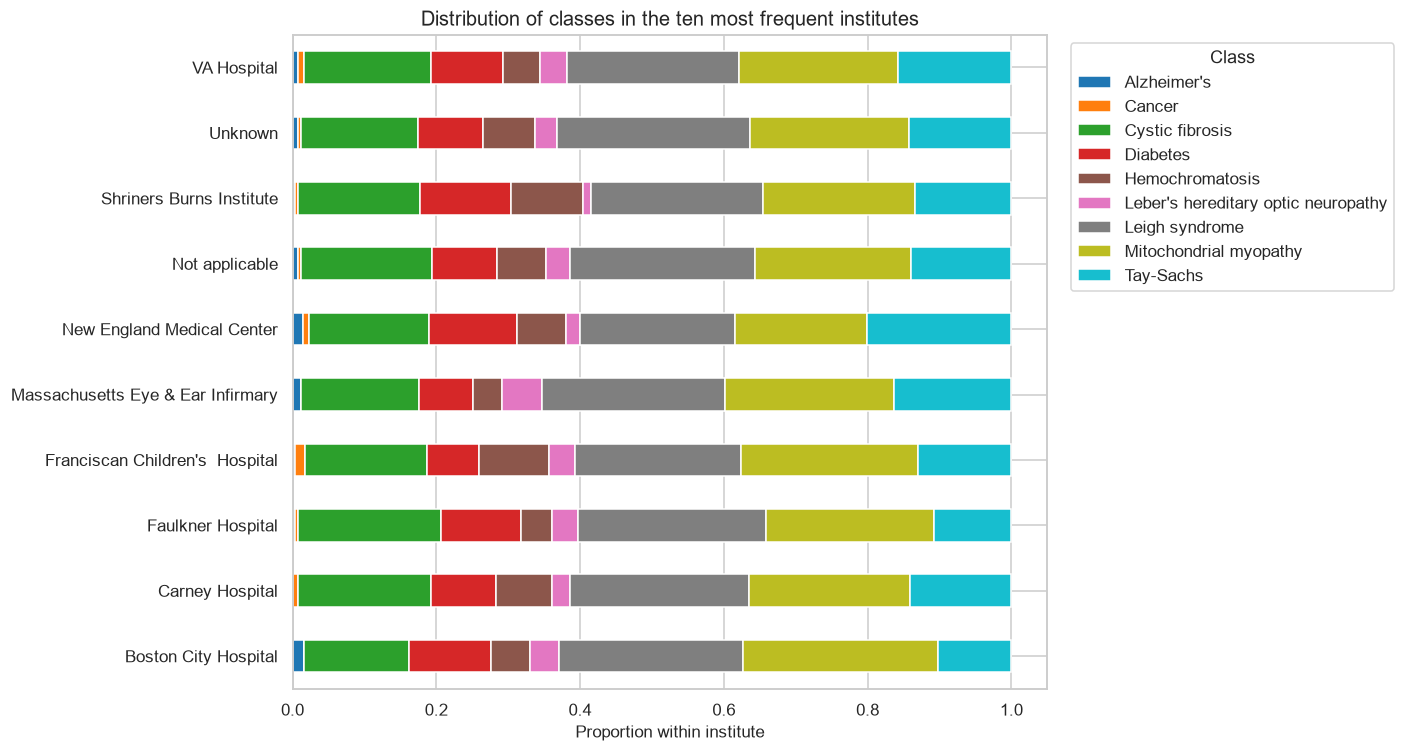

,variable,revision,decision_inicial
0,Patient Id y names,"Identifiers, not clinical characteristics",Exclude from entries
1,Status,Confirm availability at the time of prediction,Exclude for prediction prior to outcome
2,Autopsy shows birth defect (if applicable),Information from autopsy,Exclude for prediction prior to outcome
3,Follow-up,Confirm meaning and timing of registration,Exclude until availability is clarified
4,Institute Name / Location of Institute,Possible dependency on the originating center,Retain as metadata for validation
5,Genetic Disorder / Disorder Subclass,Output labels,Exclude both from entries


In [15]:
# =============================================================================
# EDA 12: INSTITUTE EFFECTS AND LEAKAGE AUDIT
# =============================================================================

institute = eda_train["Institute Name"].fillna("Unknown")

institute_counts = institute.value_counts()
display(institute_counts.to_frame("records"))

top_institutes = institute_counts.head(10).index
selected = institute.isin(top_institutes)

institute_targets = pd.crosstab(
    institute.loc[selected],
    eda_train.loc[selected, EDA_TARGET],
    normalize="index",
)

institute_targets.plot.barh(
    stacked=True,
    figsize=(13, 7),
    colormap="tab10",
)
plt.xlabel("Proportion within institute")
plt.ylabel("")
plt.title("Distribution of classes in the ten most frequent institutes")
plt.legend(title="Class", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

availability_audit = pd.DataFrame([
    {
        "variable": "Patient Id y names",
        "revision": "Identifiers, not clinical characteristics",
        "decision_inicial": "Exclude from entries",
    },
    {
        "variable": "Status",
        "revision": "Confirm availability at the time of prediction",
        "decision_inicial": "Exclude for prediction prior to outcome",
    },
    {
        "variable": "Autopsy shows birth defect (if applicable)",
        "revision": "Information from autopsy",
        "decision_inicial": "Exclude for prediction prior to outcome",
    },
    {
        "variable": "Follow-up",
        "revision": "Confirm meaning and timing of registration",
        "decision_inicial": "Exclude until availability is clarified",
    },
    {
        "variable": "Institute Name / Location of Institute",
        "revision": "Possible dependency on the originating center",
        "decision_inicial": "Retain as metadata for validation",
    },
    {
        "variable": "Genetic Disorder / Disorder Subclass",
        "revision": "Output labels",
        "decision_inicial": "Exclude both from entries",
    },
])

display(availability_audit)

# Exploratory Analysis Conclusions

The exploratory analysis focused on predicting **Disorder Subclass**, a variable with nine classes. The original training set contains 22,083 records and 45 columns, with only 19,915 including the subclass. Of these, 15,932 were used for the EDA, while 3,983 were set aside for validation. The test set comprises 9,465 records and 43 columns, lacking the two diagnostic labels.

Three findings guide the model development: data availability varies significantly across variables and datasets; the classes are highly imbalanced; and genetic background factors show clearer descriptive associations than the numerical variables analyzed.

## 1. Data Quality

**Formatting issues.** Institute names appear in various forms—for example, `VA Hospital` and `Va Hospital`; these need to be reviewed and standardized if they refer to the same institution. There are also names with repeated spaces and truncated headers, such as `Heart Rate (rates/min`. It is advisable to normalize spaces, capitalization, and column names while maintaining the link to the original fields.

**Missingness codes.** Categorical tables represent missing values ​​using the category `Unknown`. However, the shared results do not include the full inventory of original codes or the conversion rules, so I cannot state with certainty which ones were normalized. `Not applicable` was explicitly retained in the complete-case analysis and must be treated separately from unknown information, as a non-applicable status and a lack of recorded data are not necessarily the same thing.

**Constant variables.** `Test 1`, `Test 2`, `Test 3`, `Test 4`, `Test 5`, and `Parental consent` have a single value across the available observations; thus, they are not useful for distinguishing between patients. It is proposed to exclude them as content predictors and to evaluate separately whether their missingness indicators provide reproducible information, bearing in mind that availability differs between the training and test sets.

**Duplicate records.** There are no repeated identifiers or entirely duplicate rows in the original datasets, nor are identifiers shared between the training and test sets. This rules out the forms of duplication examined, though it does not eliminate the possibility of related patients or equivalent records existing under different identifiers.

## 2. Data availability

**Variables with the most missing values.** In the original training set, the highest proportions of missing data correspond to `Birth asphyxia` (54.94%), `Location of Institute` (49.50%), `Family Name` (43.88%), `H/O substance abuse` (32.77%), and `H/O radiation exposure (x-ray)` (32.01%). Maternal and paternal ages are missing in 27.33% and 27.11% of cases, respectively. ...respectively. The target subclass is missing in 2,168 records (9.82%), which are excluded from the supervised analysis of this target.

These percentages were calculated based on the original 22,083 records and should not be confused with those from the 15,932 records used in the EDA.

**Training vs. test.** Patterns of missingness vary significantly between the two sets. In the test set, heart rate and respiratory rate show nearly 53% missing data, compared to approximately 9% in the training set analyzed; the differences are 43.59 and 43.49 percentage points, respectively. `Institute Name` sees a 30.96 percentage-point increase in missing values, and `Maternal gene` sees a 27.16-point increase.

The opposite occurs with other variables: patient age, the ages of both parents, and the five symptoms are complete in the test set, despite having missing values ​​in the training set. Changes in data availability do not affect all variables equally.

Regarding observed numerical values, Kolmogorov–Smirnov statistics range from 0.005 to 0.011, indicating very little difference between empirical distributions. No new categories were reported for the categorical variables examined. None of this resolves the issue of missing data or guarantees that the relationship between predictors and the target remains consistent across both sets.

**Cost of removing incomplete records.** If complete information were required for all analyzed fields, the sample size would drop from 15,932 to 1,278 records: 8.02% would be retained, while 91.98% would be lost. All nine classes would remain represented, but this does not guarantee they would be large enough for training or evaluation purposes.

The sample composition would also shift. Patients recorded as `Alive` would rise from 50.45%... ...to 60.41%, and the `Deceased` category would drop from 49.55% to 39.59%. Therefore, imputation will be prioritized over wholesale removal. The 8.02% figure applies to the set of fields evaluated in this EDA, so the retention rate will need to be recalculated once the final predictors are defined.

## 3. Target distribution

**Majority classes.** `Leigh syndrome` accounts for 4,128 records (25.91%) and `Mitochondrial myopathy` for 3,524 (22.12%). Next are `Cystic fibrosis` with 2,758 (17.31%) and `Tay-Sachs` with 2,266 (14.22%). Together, these four make up approximately 79.56% of the analyzed training data.

**Minority classes.** The least represented are `Cancer`, with 78 records (0.49%), and `Alzheimer's`, with 122 (0.77%). `Leber's hereditary optic neuropathy` also has few cases: 518 (3.25%). The ratio between the most frequent and least frequent class is approximately 53 to 1.

**Main category and subclass.** Among records where both labels are present, each subclass belongs to a single main category, indicating a consistent hierarchical structure. The reverse is not necessarily true: a main category does not determine a single subclass.

Of the 14,449 records in the exploratory training set with an available main category, 51.18% belong to mitochondrial categories, 38.40% to monogenic hereditary diseases, and 10.42% to multifactorial disorders. These percentages use a different denominator than that used for the nine subclasses.

`Genetic Disorder` is another diagnostic label that is unavailable in the test set. Therefore, it will be excluded from the model inputs, as will `Disorder Subclass`, which will be used solely as the target.

**Validation and metrics.** Overall accuracy can mask poor performance on minority classes. The primary criterion will be the macro F1 score, accompanied by precision, recall, F1, and support per class, as well as balanced accuracy and a confusion matrix.

The partitions will be stratified to preserve the nine classes as much as possible, and the number of partitions must be compatible with the limited number of cases in the minority classes. Weighting or resampling will be tested only during the training phase of each partition, ensuring that the evaluation sets retain the original distribution.

## 4. Observed associations

**Differences between classes.** The numerical variables show significant overlap. Patient age has a median of seven years across most classes, and the number of previous abortions maintains a median of two—with an interquartile range of one to three—in all of them. Parental ages and blood counts also do not differ between classes.

Some small classes show descriptive differences, such as a median age of eight years for `Cancer` and six for `Alzheimer's`. However, these are based on few observations, so they do not support claims of stable predictive separation.

Regarding `Blood cell count (mcL)`, there are 112 observations falling outside 1.5 times the interquartile range, representing approximately 0.70% of the records. Being statistically atypical is not sufficient grounds for exclusion; the scale, units, and data quality must be reviewed first.

**Symptoms.** Each of the five symptoms has between 14,395 and 14,499 available observations, and pairwise comparisons are based on between 13,107 and 13,214 records where both symptoms were observed.

These counts describe joint availability. They do not indicate how many patients present both symptoms simultaneously or the strength of the association; consequently, the current tables do not allow for conclusions regarding specific co-occurrence or discriminative combinations. Combined characteristics remain hypotheses to be tested via ablation experiments, and their construction will require distinguishing between an absent symptom and an unrecorded one. **Potentially informative medical history factors.** The strongest categorical associations with the subclass are `Genes in mother's side` (Cramér's V of 0.201), `Inherited from father` (0.194), `Maternal gene` (0.188), and `Paternal gene` (0.166). These are the priority candidates for assessing predictive contribution, although an individual association neither proves causality nor guarantees strong out-of-sample performance.

The other categorical variables examined fall within the 0.000 to 0.019 range—indicating weak associations by this metric. A value of 0.000 does not demonstrate exact independence, nor does it rule out interactions with other predictors.

**Sample sizes and limitations.** Associations were calculated using widely varying amounts of data: ranging from 7,240 observed pairs for `Birth asphyxia` to 15,932 for the full medical history dataset. Consequently, the comparisons reflect both the strength of the association and the volume of data available for each variable.

Uncertainty is particularly significant regarding `Cancer` and `Alzheimer's`. Furthermore, `Symptom 1` through `Symptom 5` lack clinical descriptions in the provided data, limiting their interpretability. Before interpreting the coexistence of the 0–14 age group with categories like `Alzheimer's` in a clinical context, one must verify the data source and how the labels were defined.

Regarding the institutions, `Not applicable` accounts for 6,129 records and `Unknown` for 3,491—together representing approximately 60.38% of the exploratory training set. The identified centers have between 217 and 277 records per category prior to name normalization. While these counts illustrate the distribution of data sources, they do not demonstrate differences in diagnostic distribution or performance across centers.

## 5. Pipeline decisions

| Finding | Evidence | Proposed decision | Evaluation method |
| --- | --- | --- | --- |
| Significant missingness | Several variables exceed 30–50% missingness; requiring all fields to be complete leaves only 8.02% of records. | Impute numerical and categorical variables; distinguish between `Unknown` and `Not applicable`; evaluate missingness indicators. | Compare a simple imputation baseline against alternatives and indicators, using the same data partitions. |
| Availability differences between sets | In the test set, heart rate and respiratory rate show over 43 percentage points higher missingness. | Assess the model's reliance on variables with unstable availability. | Compare models with and without these variables and conduct controlled masking tests during internal validation. |
| Class imbalance | `Leigh syndrome` accounts for 25.91% and `Cancer` for 0.49%; an approximate 53:1 ratio. | Use stratified partitions and per-class metrics; test weighting or resampling during training. | Macro F1, recall and F1 per class, balanced accuracy, and variability across partitions. |
| Potential symptom co-occurrences | There are over 13,100 joint observations per pair, but counts do not quantify positive co-occurrence. | Evaluate combinations, the number of symptoms present, and the number of symptoms observed, without equating a missing record to a zero value. | Ablation study against a model using only individual symptoms. |
| Potentially informative genetic history | Cramér's V between 0.166 and 0.201 for four genetic history variables. | Evaluate their individual and joint contribution, after verifying their availability at the time of prediction. | Compare models with and without this background information under the same protocol. |
| Constant variables | `Test 1–5` and `Parental consent` have a single observed value. | Exclude their values ​​as predictors; evaluate indicators of absence separately. | Compare performance and stability with and without those indicators. |
| Potential institutional dependency | There are name variations, and 60.38% of records lack a specific identified center. | Normalize institutions and retain center and location as metadata; consider group-based validation if feasible. | Compare stratified random partitions with center-based partitions, verifying class coverage and the handling of unknown centers. |
| Post-outcome variables | `Status`, autopsy, and `Follow-up` may contain information unavailable at the intended time of prediction. | Exclude `Status` and autopsy for pre-outcome prediction; exclude `Follow-up` until its timing is clarified. | Audit the meaning, recording date, and availability of each predictor. |
| Identifiers and diagnostic labels | Identifiers and names do not describe clinical characteristics; the two labels are not part of the test. | Exclude identifiers, names, and both labels from inputs; use `Disorder Subclass` as the target. | Explicitly review input columns and verify the absence of information leakage. |
| Values ​​outside interquartile ranges | 112 extreme observations in `Blood cell count (mcL)`. | Retain them initially and verify units and quality before transforming or excluding. | Sensitivity analysis using conventional and robust scaling, fitted using only the training set. |

## 6. Transition to QNN

The EDA lays the groundwork for preparing data for both the quantum neural network (QNN) and the classical baseline models. Variable selection, encoding, imputation, scaling, and dimensionality reduction will be fitted solely using the training data from each partition, and the learned transformations will be applied to the evaluation data without refitting.

The 3,983 reserved records will be excluded from fitting and configuration selection if used for final evaluation. Hyperparameters will be determined using internal partitions of the 15,932 development records. The unlabeled test set will be used to generate predictions but not to calculate metrics until the corresponding labels become available.

The number of circuit inputs will be determined through experiments that weigh predictive performance, information retention, the number of qubits, and training cost. Details regarding encoding, circuit depth, the number of parameters, required executions or measurements, and variability across seeds will also be documented.

# Data preparation for modeling

## Objective
To build a reproducible preprocessing pipeline for a hybrid multi-task QNN
featuring a shared representation and two outputs:
classification of nine subclasses and classification of three main
categories.

Records with incomplete features will be retained, while predictors
unavailable at the time of prediction will be excluded.

## Target Variables
- Primary task: `Disorder Subclass`, with nine classes.
- Auxiliary task: `Genetic Disorder`, with three categories.

Both columns will be excluded from the model inputs. The relationship
between category and subclass will be documented via an explicit mapping
and used to promote consistency between both outputs.

## Partitions
- Development: records used in EDA.
- Final evaluation: patients previously set aside, with no involvement
in feature selection, hyperparameter tuning, or architecture design.
- External test: unlabeled records intended for prediction.

Records with an available main category but a missing subclass may be
included in the development set only, after verifying that their
identifiers do not match those of the patients set aside.

A consistent patient-level assignment will be maintained for both tasks.
Configuration selection will be performed via internal cross-validation,
preserving subclass representation as much as possible and distributing
records with only the category available in a stratified manner based
on that category.

## Handling Incomplete Labels
Records with at least one available label may contribute to
supervised training.

Each classification loss will be calculated solely based on records
possessing the corresponding label, using availability masks and
normalization by valid observations.

Unknown labels will not be imputed. Records lacking any labels will be
excluded from the supervised training phase of this experiment.

## Predictor Selection
The following will be excluded:
- Identifiers and personal names.
- The two diagnostic labels. - `Status` and autopsy information.
- `Follow-up`, pending confirmation of its availability at prediction time.
- Constant values ​​for `Test 1–5` and `Parental consent`.

The institute and its location will be retained as audit metadata,
without initially including them as predictors.

## Preprocessing
- Normalize formats and missing-value codes using explicit rules.
- Maintain the distinction between unknown information and `Not applicable`.
- Impute numerical variables using the training set median.
- Standardize numerical variables.
- Represent categorical missing values ​​with an explicit category.
- Apply one-hot encoding to categorical variables and binary symptoms.
- Handle categories not observed during fitting without refitting
the encoder using evaluation data.

The initial representation will use the eligible original predictors,
without automatically adding interaction terms.

## Shared representation for the QNN
Feature selection or dimensionality reduction will be performed jointly
for both tasks, without partitioning the data into category-specific experts.

The method and input dimension will be selected via internal
validation, considering the macro-F1 score of the nine subclasses,
the number of qubits, and training cost.

The resulting features will feed into the classical layers,
the variational quantum circuit, and the two classification heads.

## Imbalance and multi-task training
Class-weighted classification losses will be used.
Weights will be calculated separately for each task, using
only the labels available in the training partition.

The joint loss will combine:
- Primary classification of nine subclasses.
- Auxiliary classification of three categories.
- Consistency between category probabilities and the sum
of their subclass probabilities.

The relative weights of these losses will be selected via
internal validation. No resampling will be applied initially.

## Information leakage assessment and prevention
The macro-F1 score across the nine subclasses will serve as the primary selection criterion.
Class-specific metrics, balanced accuracy, confusion matrices,
and auxiliary task performance will also be reported.

Any transformation learned from the data will be fitted exclusively
within the corresponding training partition. It will be applied
to the validation and test sets without refitting.

Early stopping and configuration selection will rely
solely on internal validation. The final hold-out set will be evaluated
once the procedure has concluded.

The implementation will utilize Qiskit Machine Learning and Aer with GPU
for quantum simulation, and PyTorch with CUDA for the classical layers.
Experiment seeds, versions, and configurations will be recorded.

In [16]:
# =============================================================================
# MODELING 1: MULTITASK DATA CONFIGURATION AND PATIENT PARTITIONS
# =============================================================================

MODEL_SEED = 42
PATIENT_ID = "Patient Id"

MAIN_TARGET = "Disorder Subclass"
AUX_TARGET = "Genetic Disorder"
MODEL_TARGETS = [MAIN_TARGET, AUX_TARGET]

MISSING_LABEL = -100
N_SPLITS = 3
BATCH_SIZE = 64

# Initial shared representation, to be assessed in internal validation.
# This is not necessarily the number of circuit qubits.
PCA_COMPONENTS = 8

required_objects = ["eda_all", "eda_train", "eda_valid", "eda_test"]
missing_objects = [
    name for name in required_objects if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        f"Run the EDA preparation cells first: {missing_objects}"
    )

# Patient identifiers must support unambiguous partition assignment.
for name, frame in [
    ("Full labeled source", eda_all),
    ("EDA development", eda_train),
    ("Final holdout", eda_valid),
    ("External test", eda_test),
]:
    if frame[PATIENT_ID].isna().any():
        raise ValueError(f"{name}: missing patient identifiers.")

    if frame[PATIENT_ID].duplicated().any():
        raise ValueError(f"{name}: duplicated patient identifiers.")

dev_ids_existing = set(eda_train[PATIENT_ID])
holdout_ids = set(eda_valid[PATIENT_ID])
external_ids = set(eda_test[PATIENT_ID])

if dev_ids_existing & holdout_ids:
    raise ValueError("Development and holdout share patient identifiers.")

if (set(eda_all[PATIENT_ID]) & external_ids):
    raise ValueError("The source dataset and external test share patients.")

# Add only patients with an observed auxiliary target and missing main target.
auxiliary_only = eda_all.loc[
    eda_all[MAIN_TARGET].isna()
    & eda_all[AUX_TARGET].notna()
    & ~eda_all[PATIENT_ID].isin(dev_ids_existing | holdout_ids)
].copy()

development_data = pd.concat(
    [eda_train.copy(), auxiliary_only],
    ignore_index=True,
)

holdout_data = eda_valid.copy().reset_index(drop=True)
external_data = eda_test.copy().reset_index(drop=True)

assert not development_data[PATIENT_ID].duplicated().any()
assert not set(development_data[PATIENT_ID]) & holdout_ids
assert development_data[MODEL_TARGETS].notna().any(axis=1).all()

partition_summary = pd.DataFrame([
    {
        "partition": name,
        "patients": len(frame),
        "main_label_available": frame[MAIN_TARGET].notna().sum(),
        "aux_label_available": frame[AUX_TARGET].notna().sum(),
        "both_labels_available": (
            frame[MODEL_TARGETS].notna().all(axis=1).sum()
        ),
    }
    for name, frame in [
        ("Development", development_data),
        ("Final holdout", holdout_data),
    ]
])

display(partition_summary)
print("Additional auxiliary-only patients:", len(auxiliary_only))
print("External test patients:", len(external_data))

,partition,patients,main_label_available,aux_label_available,both_labels_available
0,Development,17822,15932,16339,14449
1,Final holdout,3983,3983,3598,3598


Additional auxiliary-only patients: 1890
External test patients: 9465


In [17]:
# =============================================================================
# MODELING 2: FEATURE ELIGIBILITY AND CENTRALIZED SCHEMA
# =============================================================================

EXCLUSION_GROUPS = {
    "Targets": MODEL_TARGETS,
    "Identifiers": [
        "Patient Id",
        "Patient First Name",
        "Family Name",
        "Father's name",
    ],
    "Institutional metadata": [
        "Institute Name",
        "Location of Institute",
    ],
    "Unavailable or uncertain at prediction time": [
        "Status",
        "Autopsy shows birth defect (if applicable)",
        "Follow-up",
    ],
    "Constant observed values": [
        "Test 1", "Test 2", "Test 3", "Test 4", "Test 5",
        "Parental consent",
    ],
}

EXCLUDED_FEATURES = {
    column
    for columns in EXCLUSION_GROUPS.values()
    for column in columns
}

FEATURE_COLUMNS = [
    column for column in development_data.columns
    if column not in EXCLUDED_FEATURES
]

for name, frame in [
    ("Final holdout", holdout_data),
    ("External test", external_data),
]:
    missing = set(FEATURE_COLUMNS) - set(frame.columns)
    if missing:
        raise ValueError(f"{name}: missing predictors {sorted(missing)}")

# Raw normalized inputs; no fitted preprocessing yet.
X_dev = development_data[FEATURE_COLUMNS].copy()
X_holdout = holdout_data[FEATURE_COLUMNS].copy()
X_external_test = external_data[FEATURE_COLUMNS].copy()

Y_dev = development_data[MODEL_TARGETS].copy()
Y_holdout = holdout_data[MODEL_TARGETS].copy()

external_test_ids = external_data[PATIENT_ID].copy()

symptom_columns = [
    f"Symptom {i}"
    for i in range(1, 6)
    if f"Symptom {i}" in FEATURE_COLUMNS
]

detected_categorical = X_dev.select_dtypes(
    include=["object", "string", "category", "bool"]
).columns.tolist()

MODEL_CATEGORICAL_COLUMNS = [
    column for column in FEATURE_COLUMNS
    if column in detected_categorical or column in symptom_columns
]

MODEL_NUMERIC_COLUMNS = [
    column for column in X_dev.select_dtypes(include="number").columns
    if column not in MODEL_CATEGORICAL_COLUMNS
]

classified = set(
    MODEL_NUMERIC_COLUMNS + MODEL_CATEGORICAL_COLUMNS
)

if classified != set(FEATURE_COLUMNS):
    raise ValueError(
        f"Unclassified predictors: {set(FEATURE_COLUMNS) - classified}"
    )

assert not set(MODEL_TARGETS) & set(FEATURE_COLUMNS)
assert not set(MODEL_NUMERIC_COLUMNS) & set(MODEL_CATEGORICAL_COLUMNS)

feature_schema = pd.DataFrame({
    "variable": FEATURE_COLUMNS,
    "dtype": [str(X_dev[c].dtype) for c in FEATURE_COLUMNS],
    "modeling_type": [
        "numeric" if c in MODEL_NUMERIC_COLUMNS else "categorical"
        for c in FEATURE_COLUMNS
    ],
    "missing_development_%": [
        100 * X_dev[c].isna().mean() for c in FEATURE_COLUMNS
    ],
})

display(feature_schema.round(2))
print("Eligible predictors:", len(FEATURE_COLUMNS))

,variable,dtype,modeling_type,missing_development_%
0,Patient Age,float64,numeric,6.50
1,Genes in mother's side,object,categorical,0.00
2,Inherited from father,object,categorical,1.41
3,Maternal gene,object,categorical,12.86
4,Paternal gene,object,categorical,0.00
5,Blood cell count (mcL),float64,numeric,0.00
6,Mother's age,float64,numeric,27.49
7,Father's age,float64,numeric,27.09
8,Respiratory Rate (breaths/min),object,categorical,9.70
9,Heart Rate (rates/min,object,categorical,9.57


Eligible predictors: 28


In [18]:
# =============================================================================
# MODELING 3: TARGET ENCODING, MASKS AND HIERARCHY
# =============================================================================

main_encoder = LabelEncoder().fit(Y_dev[MAIN_TARGET].dropna())
aux_encoder = LabelEncoder().fit(Y_dev[AUX_TARGET].dropna())

N_MAIN_CLASSES = len(main_encoder.classes_)
N_AUX_CLASSES = len(aux_encoder.classes_)

if (N_MAIN_CLASSES, N_AUX_CLASSES) != (9, 3):
    raise ValueError(
        f"Expected 9 and 3 classes; found "
        f"{N_MAIN_CLASSES} and {N_AUX_CLASSES}."
    )


def encode_observed_labels(series, encoder):
    encoded = np.full(len(series), MISSING_LABEL, dtype=np.int64)
    observed = series.notna().to_numpy()

    if observed.any():
        values = series.loc[series.notna()]
        unknown = set(values) - set(encoder.classes_)

        if unknown:
            raise ValueError(f"Unknown target labels: {sorted(unknown)}")

        encoded[observed] = encoder.transform(values)

    return encoded


# All encoded labels refer to development only at this stage.
y_main_dev = encode_observed_labels(Y_dev[MAIN_TARGET], main_encoder)
y_aux_dev = encode_observed_labels(Y_dev[AUX_TARGET], aux_encoder)

main_mask_dev = y_main_dev != MISSING_LABEL
aux_mask_dev = y_aux_dev != MISSING_LABEL

complete_pairs = Y_dev.dropna(subset=MODEL_TARGETS)

parents_per_subclass = complete_pairs.groupby(
    MAIN_TARGET
)[AUX_TARGET].nunique()

if not parents_per_subclass.eq(1).all():
    raise ValueError("Conflicting category–subclass relationships.")

parent_by_subclass = (
    complete_pairs
    .drop_duplicates(subset=[MAIN_TARGET])
    .set_index(MAIN_TARGET)[AUX_TARGET]
    .to_dict()
)

missing_mappings = (
    set(main_encoder.classes_) - set(parent_by_subclass)
)

if missing_mappings:
    raise ValueError(
        f"No observed parent category for: {sorted(missing_mappings)}"
    )

# Matrix shape: (9 subclasses, 3 parent categories).
# Future use: parent_probabilities = subclass_probabilities @ hierarchy_matrix.
hierarchy_matrix_np = np.zeros(
    (N_MAIN_CLASSES, N_AUX_CLASSES),
    dtype=np.float32,
)

hierarchy_rows = []

for main_index, subclass in enumerate(main_encoder.classes_):
    parent = parent_by_subclass[subclass]
    aux_index = int(aux_encoder.transform([parent])[0])

    hierarchy_matrix_np[main_index, aux_index] = 1.0

    hierarchy_rows.append({
        "subclass_code": main_index,
        "subclass": subclass,
        "category_code": aux_index,
        "category": parent,
    })

assert np.all(hierarchy_matrix_np.sum(axis=1) == 1)

display(pd.DataFrame(hierarchy_rows))

print("Observed main labels:", main_mask_dev.sum())
print("Observed auxiliary labels:", aux_mask_dev.sum())
print("Hierarchy matrix shape:", hierarchy_matrix_np.shape)

,subclass_code,subclass,category_code,category
0,0,Alzheimer's,1,Multifactorial genetic inheritance disorders
1,1,Cancer,1,Multifactorial genetic inheritance disorders
2,2,Cystic fibrosis,2,Single-gene inheritance diseases
3,3,Diabetes,1,Multifactorial genetic inheritance disorders
4,4,Hemochromatosis,2,Single-gene inheritance diseases
5,5,Leber's hereditary optic neuropathy,0,Mitochondrial genetic inheritance disorders
6,6,Leigh syndrome,0,Mitochondrial genetic inheritance disorders
7,7,Mitochondrial myopathy,0,Mitochondrial genetic inheritance disorders
8,8,Tay-Sachs,2,Single-gene inheritance diseases


Observed main labels: 15932
Observed auxiliary labels: 16339
Hierarchy matrix shape: (9, 3)


In [19]:
# =============================================================================
# MODELING 4: SHARED INTERNAL CROSS-VALIDATION
# =============================================================================

strata = np.where(
    main_mask_dev,
    "subclass::" + Y_dev[MAIN_TARGET].fillna("").astype(str),
    "category_only::" + Y_dev[AUX_TARGET].fillna("").astype(str),
)

strata_counts = pd.Series(strata).value_counts()

if strata_counts.min() < N_SPLITS:
    raise ValueError(
        f"The smallest stratum has {strata_counts.min()} patients. "
        f"Reduce N_SPLITS, currently {N_SPLITS}."
    )

cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=MODEL_SEED,
)

CV_SPLITS = [
    (train_idx, valid_idx)
    for train_idx, valid_idx in cv.split(X_dev, strata)
]

fold_assignment = np.full(len(X_dev), -1, dtype=int)
fold_rows = []

for fold, (train_idx, valid_idx) in enumerate(CV_SPLITS):
    assert not np.intersect1d(train_idx, valid_idx).size

    fold_assignment[valid_idx] = fold

    # Every training fold must contain all output classes.
    for labels, expected in [
        (y_main_dev, N_MAIN_CLASSES),
        (y_aux_dev, N_AUX_CLASSES),
    ]:
        observed_train = labels[train_idx]
        observed_train = observed_train[observed_train != MISSING_LABEL]

        assert len(np.unique(observed_train)) == expected

    fold_rows.append({
        "fold": fold,
        "training_patients": len(train_idx),
        "validation_patients": len(valid_idx),
        "validation_main_labels": main_mask_dev[valid_idx].sum(),
        "validation_aux_labels": aux_mask_dev[valid_idx].sum(),
    })

assert (fold_assignment >= 0).all()

partition_manifest = pd.DataFrame({
    PATIENT_ID: development_data[PATIENT_ID].to_numpy(),
    "internal_validation_fold": fold_assignment,
    "main_label_available": main_mask_dev,
    "aux_label_available": aux_mask_dev,
})

display(pd.DataFrame(fold_rows))

,fold,training_patients,validation_patients,validation_main_labels,validation_aux_labels
0,0,11881,5941,5311,5448
1,1,11881,5941,5311,5438
2,2,11882,5940,5310,5453


In [20]:
# =============================================================================
# MODELING 5: SHARED PREPROCESSING FACTORY & OPTIMAL PCA SEARCH (>= 95%)
# =============================================================================

def categorical_values_to_text(data):
    """Preserve missingness while unifying categorical representations."""
    result = pd.DataFrame(data).copy()

    for column in result.columns:
        values = result[column].astype("string")
        result[column] = values.astype(object).where(
            values.notna(), np.nan
        )

    return result


def find_optimal_pca_components(X_train, variance_threshold=0.95):
    """
    Fits a full PCA on the processed training data,
    prints the information retained in each component,
    and returns the minimum number of components required to reach the threshold (e.g., 95%).
    """
    print("\n" + "=" * 60)
    print("INITIATING PCA COMPONENT SEARCH (Threshold >= 95%)")
    print("=" * 60)
    
    # 1. Ajustar PCA con todos los componentes posibles para evaluar la varianza
    full_pca = PCA(n_components=None, svd_solver="full")
    full_pca.fit(X_train)
    
    explained_variance_ratio = full_pca.explained_variance_ratio_
    cumulative_variance = np.cumsum(explained_variance_ratio)
    
    optimal_components = None
    
    # 2. Imprimir cada prueba / componente con su información retenida
    for i, (ind_var, cum_var) in enumerate(zip(explained_variance_ratio, cumulative_variance), start=1):
        percentage_ind = ind_var * 100
        percentage_cum = cum_var * 100
        print(f"PCA Test {i:3d} | Individual Variance: {percentage_ind:6.2f}% | Cumulative Variance: {percentage_cum:6.2f}%")
        
        # Find the first point where the threshold is reached or exceeded (95%)
        if cum_var >= variance_threshold and optimal_components is None:
            optimal_components = i

    print("-" * 60)
    print(f"-> Optimal components needed to retain at least the {variance_threshold * 100}%: {optimal_components}")
    print("=" * 60 + "\n")
    
    return optimal_components


def build_multitask_preprocessor(n_components=None):
    numeric_pipeline = Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="median",
                keep_empty_features=True,
            ),
        ),
        ("scaler", StandardScaler()),
    ])

    categorical_pipeline = Pipeline([
        (
            "normalize_types",
            FunctionTransformer(
                categorical_values_to_text,
                validate=False,
                feature_names_out="one-to-one",
            ),
        ),
        (
            "imputer",
            SimpleImputer(
                strategy="constant",
                fill_value="Unknown",
                keep_empty_features=True,
            ),
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False,
            ),
        ),
    ])

    columns = ColumnTransformer([
        ("numeric", numeric_pipeline, MODEL_NUMERIC_COLUMNS),
        (
            "categorical",
            categorical_pipeline,
            MODEL_CATEGORICAL_COLUMNS,
        ),
    ])

    steps = [
        ("columns", columns),
        # Remove dimensions constant within the training fold.
        ("remove_constants", VarianceThreshold(threshold=0.0)),
    ]

    if n_components is not None:
        steps.append((
            "pca",
            PCA(
                n_components=n_components,
                svd_solver="full",
            ),
        ))

    return Pipeline(steps)


print("Preprocessing factory & PCA search functions defined.")

Preprocessing factory & PCA search functions defined.


In [21]:
# =============================================================================
# MODELING 6: FOLD-SPECIFIC ARRAYS, CLASS WEIGHTS & DYNAMIC PCA OPTIMIZATION
# =============================================================================

def balanced_task_weights(labels, n_classes):
    """Inverse-frequency weights using observed training labels only."""
    observed = labels[labels != MISSING_LABEL]
    counts = np.bincount(observed, minlength=n_classes)

    if np.any(counts == 0):
        raise ValueError("A training fold is missing a target class.")

    weights = len(observed) / (n_classes * counts)
    return weights.astype(np.float32), counts


def prepare_multitask_fold(fold):
    train_idx, valid_idx = CV_SPLITS[fold]

    print(f"\n--- Procesando Fold {fold} ---")
    
    # 1. Obtener datos base preprocesados (sin PCA) para evaluar la varianza
    base_preprocessor = build_multitask_preprocessor(n_components=None)
    X_train_base = base_preprocessor.fit_transform(X_dev.iloc[train_idx])

    # 2. Búsqueda automática de componentes PCA para retener >= 95% de información
    optimal_components = find_optimal_pca_components(X_train_base, variance_threshold=0.95)

    # 3. Construir el preprocesador final utilizando los componentes óptimos calculados
    preprocessor = build_multitask_preprocessor(n_components=optimal_components)

    X_train_array = preprocessor.fit_transform(
        X_dev.iloc[train_idx]
    )
    X_valid_array = preprocessor.transform(
        X_dev.iloc[valid_idx]
    )

    X_train_array = np.ascontiguousarray(
        X_train_array, dtype=np.float32
    )
    X_valid_array = np.ascontiguousarray(
        X_valid_array, dtype=np.float32
    )

    if not (
        np.isfinite(X_train_array).all()
        and np.isfinite(X_valid_array).all()
    ):
        raise ValueError("Non-finite values after preprocessing.")

    main_weights, main_counts = balanced_task_weights(
        y_main_dev[train_idx], N_MAIN_CLASSES
    )
    aux_weights, aux_counts = balanced_task_weights(
        y_aux_dev[train_idx], N_AUX_CLASSES
    )

    return {
        "fold": fold,
        "preprocessor": preprocessor,
        "train_idx": train_idx,
        "valid_idx": valid_idx,
        "X_train": X_train_array,
        "X_valid": X_valid_array,
        "y_main_train": y_main_dev[train_idx],
        "y_main_valid": y_main_dev[valid_idx],
        "y_aux_train": y_aux_dev[train_idx],
        "y_aux_valid": y_aux_dev[valid_idx],
        "main_mask_train": main_mask_dev[train_idx],
        "main_mask_valid": main_mask_dev[valid_idx],
        "aux_mask_train": aux_mask_dev[train_idx],
        "aux_mask_valid": aux_mask_dev[valid_idx],
        "main_weights": main_weights,
        "aux_weights": aux_weights,
        "main_counts": main_counts,
        "aux_counts": aux_counts,
    }


# Prepare the first internal fold for the next model-building cells.
FOLD_INDEX = 0
fold_data = prepare_multitask_fold(FOLD_INDEX)

print("Internal fold:", FOLD_INDEX)
print("Training matrix:", fold_data["X_train"].shape)
print("Validation matrix:", fold_data["X_valid"].shape)

display(pd.DataFrame({
    "subclass": main_encoder.classes_,
    "training_count": fold_data["main_counts"],
    "loss_weight": fold_data["main_weights"],
}).round(3))

display(pd.DataFrame({
    "category": aux_encoder.classes_,
    "training_count": fold_data["aux_counts"],
    "loss_weight": fold_data["aux_weights"],
}).round(3))

if "pca" in fold_data["preprocessor"].named_steps:
    pca_step = fold_data["preprocessor"].named_steps["pca"]
    n_components_obtained = pca_step.n_components_
    explained_variance = pca_step.explained_variance_ratio_.sum()
    
    print("-" * 60)
    print(f"Number of principal components obtained: {n_components_obtained}")
    print(f"Training variance retained by PCA: {explained_variance:.2%}")
    print("-" * 60)


--- Procesando Fold 0 ---

INITIATING PCA COMPONENT SEARCH (Threshold >= 95%)
PCA Test   1 | Individual Variance:   5.38% | Cumulative Variance:   5.38%
PCA Test   2 | Individual Variance:   5.33% | Cumulative Variance:  10.71%
PCA Test   3 | Individual Variance:   5.22% | Cumulative Variance:  15.93%
PCA Test   4 | Individual Variance:   5.19% | Cumulative Variance:  21.12%
PCA Test   5 | Individual Variance:   5.14% | Cumulative Variance:  26.26%
PCA Test   6 | Individual Variance:   5.03% | Cumulative Variance:  31.30%
PCA Test   7 | Individual Variance:   2.80% | Cumulative Variance:  34.10%
PCA Test   8 | Individual Variance:   2.69% | Cumulative Variance:  36.78%
PCA Test   9 | Individual Variance:   2.50% | Cumulative Variance:  39.28%
PCA Test  10 | Individual Variance:   2.45% | Cumulative Variance:  41.73%
PCA Test  11 | Individual Variance:   2.43% | Cumulative Variance:  44.15%
PCA Test  12 | Individual Variance:   2.39% | Cumulative Variance:  46.55%
PCA Test  13 | Indivi

,subclass,training_count,loss_weight
0,Alzheimer's,81,14.569
1,Cancer,52,22.694
2,Cystic fibrosis,1839,0.642
3,Diabetes,969,1.218
4,Hemochromatosis,723,1.632
5,Leber's hereditary optic neuropathy,346,3.411
6,Leigh syndrome,2752,0.429
7,Mitochondrial myopathy,2349,0.502
8,Tay-Sachs,1510,0.782


,category,training_count,loss_weight
0,Mitochondrial genetic inheritance disorders,5569,0.652
1,Multifactorial genetic inheritance disorders,1140,3.185
2,Single-gene inheritance diseases,4182,0.868


------------------------------------------------------------
Number of principal components obtained: 44
Training variance retained by PCA: 95.01%
------------------------------------------------------------


In [22]:
# =============================================================================
# MODELING 7: MULTITASK TENSORS AND TRAINING LOADERS (CPU / GPU COMPATIBLE)
# =============================================================================

# Configuración de dispositivo flexible (usa CUDA si está disponible, de lo contrario CPU)
if "device" not in globals():
    device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
else:
    device = torch.device(device)

print(f"Using PyTorch device: {device}")


def make_multitask_dataset(data, partition):
    return TensorDataset(
        torch.from_numpy(data[f"X_{partition}"]),
        torch.from_numpy(data[f"y_main_{partition}"]),
        torch.from_numpy(data[f"y_aux_{partition}"]),
        torch.from_numpy(data[f"main_mask_{partition}"]),
        torch.from_numpy(data[f"aux_mask_{partition}"]),
    )


def build_fold_loaders(data, batch_size=BATCH_SIZE, seed=MODEL_SEED):
    generator = torch.Generator()
    generator.manual_seed(seed)

    train_dataset = make_multitask_dataset(data, "train")
    valid_dataset = make_multitask_dataset(data, "valid")

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        generator=generator,
        num_workers=0,
        pin_memory=True if device.type == "cuda" else False,
        drop_last=False,
    )

    valid_loader = DataLoader(
        valid_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0,
        pin_memory=True if device.type == "cuda" else False,
        drop_last=False,
    )

    return train_loader, valid_loader


train_loader, valid_loader = build_fold_loaders(fold_data)

main_class_weights = torch.as_tensor(
    fold_data["main_weights"],
    dtype=torch.float32,
    device=device,
)

aux_class_weights = torch.as_tensor(
    fold_data["aux_weights"],
    dtype=torch.float32,
    device=device,
)

hierarchy_matrix = torch.as_tensor(
    hierarchy_matrix_np,
    dtype=torch.float32,
    device=device,
)

N_MODEL_INPUTS = fold_data["X_train"].shape[1]

# Resumen de configuración impreso en formato de tabla
summary_table = pd.DataFrame({
    "Component / Metric": [
        "PyTorch Device",
        "Model Inputs",
        "Main Outputs",
        "Auxiliary Outputs",
        "Training Batches",
        "Validation Batches"
    ],
    "Value": [
        str(device),
        N_MODEL_INPUTS,
        N_MAIN_CLASSES,
        N_AUX_CLASSES,
        len(train_loader),
        len(valid_loader)
    ]
})

display(summary_table)

# Each batch contains:
# X, y_main, y_aux, main_mask, auxiliary_mask
#
# Inside the training loop:
# X, y_main, y_aux, main_mask, aux_mask = [
#     tensor.to(device, non_blocking=True)
#     for tensor in batch
# ]

Using PyTorch device: cpu


,Component / Metric,Value
0,PyTorch Device,cpu
1,Model Inputs,44
2,Main Outputs,9
3,Auxiliary Outputs,3
4,Training Batches,186
5,Validation Batches,93


# Construction and selection of the hybrid multi-task QNN

## Objective

The plan is to build a hybrid quantum-classical neural network with a shared representation and two outputs, and to select the number of qubits that yields the highest average macro-F1 score across the nine subclasses during internal validation.

The search aims to find the best configuration among the evaluated candidates within the set training budget; it does not claim to demonstrate a global optimum.

## Classification tasks

- Primary task: `Disorder Subclass`, with nine classes.
- Auxiliary task: `Genetic Disorder`, with three categories.

The auxiliary task provides supervision for the shared representation. An inconsistency penalty is added, comparing category probabilities with the aggregated probabilities of their corresponding subclasses.

## Architecture

1. Input: 45 PCA components.
2. Classical layer: 32 units with GELU activation.
3. Trainable projection to match the number of circuit angles.
4. Tanh activation and multiplication by π to bound the angles.
5. Variational circuit with RY encoding, trainable RY and RZ rotations, and entanglement between neighboring qubits.
6. Measurement of the Pauli Z expectation value on each qubit.
7. Primary classification head with nine outputs.
8. Auxiliary classification head with three outputs.

The heads output logits, which feed into the classification loss functions. When probabilities are required, they are obtained via softmax.

## Search space

Circuits with 4, 6, and 8 qubits will be tested, starting from this initial configuration:

| Parameter | Value |
| --- | --- |
| PCA components | 45 |
| Classical hidden layer units | 32 |
| Variational layers | 2 |
| Batch size | 64 |
| Optimizer | AdamW |
| Learning rate | 0.001 |
| Weight decay | 0.0001 |
| Maximum epochs | 25 |
| Early stopping patience | 5 epochs |
| Main loss weight | 1.0 |
| Auxiliary loss weight | 0.3 |
| Hierarchical consistency weight | 0.1 |

These are initial values, not parameters proven to be optimal.

Changing the number of qubits also modifies the dimensions of the classical projection, the output heads, and the total number of trainable parameters. These differences will be recorded to facilitate the interpretation of the comparison.

## Validation protocol

The five internal partitions defined during data preparation will be used. All candidates are evaluated under equal conditions:

- the same training and validation patients in each partition;
- the same preprocessing, fitted within each partition;
- the same PCA representation within each partition;
- the same seed assigned to each partition;
- the same epoch limit and early stopping criterion.

The search comprises 15 training runs: three candidates across five partitions.

At this stage, there are no additional repetitions per seed, so the dispersion across partitions does not capture the full potential variability of the training process.

## Loss function

The total loss combines three terms:

L_total = L_subclass + 0.3 × L_category + 0.1 × L_consistency

The classification losses use per-class weights, calculated solely based on the labels available during training for each partition.

Missing labels are excluded using masks. If a batch lacks labels for a specific task, the supervised loss for that task is zero.

Consistency is measured using the Jensen–Shannon divergence between the category output and the subclass probabilities, aggregated according to the hierarchical mapping. ## Training and selection

Early stopping is guided by the macro-F1 score of the nine subclasses during internal validation; for each training run, the model state corresponding to the highest observed value is preserved.

The number of qubits is selected based on the highest average macro-F1 score across the five partitions. In the event of an exact tie, the candidate with fewer qubits is chosen.

Additionally, the following metrics will be recorded:

- the standard deviation of the macro-F1 score across partitions;
- the balanced accuracy of the nine subclasses;
- the macro-F1 score of the three categories;
- the best epoch for each training run;
- training and validation times;
- the number of classical and quantum parameters;
- the circuit depth.

## Execution environment

- Qiskit Machine Learning for the QNN.
- TorchConnector to interface the circuit with PyTorch.
- PyTorch with CUDA for classical layers.
- Qiskit Aer with GPU support for quantum simulation.
- Ideal simulation using statevectors and analytical expectation values.
- Quantum gradients via the parameter-shift rule.

Before launching the search, checks will be performed to ensure execution runs on the GPU, input dimensions are correct, and gradients propagate properly.

Preprocessing and part of the communication between PyTorch and Qiskit will continue to run on the CPU.

# Scope of results

Internal validation results are used to select the configuration; therefore, they do not constitute a final, independent performance estimate. The final hold-out set and the external test set are excluded from qubit selection and early stopping.

## Deliverables

- Architecture parameterizable by number of qubits.
- Verification of execution and gradients.
- Training history per candidate and partition.
- Checkpoints of the best state from each training run.
- Comparative table of performance and computational cost.
- Selected number of qubits.

## Subsequent stage

The configuration and number of epochs will be fixed using only internal results. Subsequently, preprocessing will be readjusted based on the entire development set, and the final model will be trained starting from a new, documented initialization.

In [23]:
# =============================================================================
# QNN 2: SEARCH CONFIGURATION AND FOLD PREPROCESSING (DYNAMIC PCA >= 95%)
# =============================================================================

SEARCH_CONFIG = {
    "qubits": [2, 4, 6],
    "circuit_layers": 2,
    "hidden_width": 32,
    "batch_size": 64,
    "max_epochs": 25,
    "patience": 5,
    "learning_rate": 1e-3,
    "weight_decay": 1e-4,
    "aux_loss_weight": 0.3,
    "consistency_loss_weight": 0.1,
    "seed": MODEL_SEED,
}

def build_search_loaders(data, batch_size, seed):
    """Create the specific DataLoaders for each iteration of the qubit search."""
    generator = torch.Generator()
    generator.manual_seed(seed)

    train_dataset = make_multitask_dataset(data, "train")
    valid_dataset = make_multitask_dataset(data, "valid")

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        generator=generator,
        num_workers=0,
        pin_memory=True if device.type == "cuda" else False,
        drop_last=False,
    )

    valid_loader = DataLoader(
        valid_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0,
        pin_memory=True if device.type == "cuda" else False,
        drop_last=False,
    )

    return train_loader, valid_loader

# These are initial fixed settings, not optimized values.
FOLD_CACHE = {}

for fold in range(len(CV_SPLITS)):
    # Llamamos a la función para procesar el fold con PCA dinámico
    prepared = prepare_multitask_fold(fold=fold)

    fitted_pca = prepared["preprocessor"].named_steps.get("pca")

    if fitted_pca is None:
        raise RuntimeError(
            f"Fold {fold}: The preprocessor does not include a PCA step."
        )

    # Validamos que se cumpla el umbral mínimo del 95% de información retenida
    explained_variance = fitted_pca.explained_variance_ratio_.sum()
    if explained_variance < 0.95:
        raise RuntimeError(
            f"Fold {fold}: The explained variance ({explained_variance:.2%}) is below the 95% threshold."
        )

    FOLD_CACHE[fold] = prepared

display(pd.DataFrame([
    {
        "fold": fold,
        "training_patients": len(data["X_train"]),
        "validation_patients": len(data["X_valid"]),
        "inputs": data["X_train"].shape[1],
        "explained_variance": (
            data["preprocessor"]
            .named_steps["pca"]
            .explained_variance_ratio_
            .sum()
        ),
    }
    for fold, data in FOLD_CACHE.items()
]))

print(
    "Total training runs:",
    len(SEARCH_CONFIG["qubits"]) * len(FOLD_CACHE),
)


--- Procesando Fold 0 ---

INITIATING PCA COMPONENT SEARCH (Threshold >= 95%)
PCA Test   1 | Individual Variance:   5.38% | Cumulative Variance:   5.38%
PCA Test   2 | Individual Variance:   5.33% | Cumulative Variance:  10.71%
PCA Test   3 | Individual Variance:   5.22% | Cumulative Variance:  15.93%
PCA Test   4 | Individual Variance:   5.19% | Cumulative Variance:  21.12%
PCA Test   5 | Individual Variance:   5.14% | Cumulative Variance:  26.26%
PCA Test   6 | Individual Variance:   5.03% | Cumulative Variance:  31.30%
PCA Test   7 | Individual Variance:   2.80% | Cumulative Variance:  34.10%
PCA Test   8 | Individual Variance:   2.69% | Cumulative Variance:  36.78%
PCA Test   9 | Individual Variance:   2.50% | Cumulative Variance:  39.28%
PCA Test  10 | Individual Variance:   2.45% | Cumulative Variance:  41.73%
PCA Test  11 | Individual Variance:   2.43% | Cumulative Variance:  44.15%
PCA Test  12 | Individual Variance:   2.39% | Cumulative Variance:  46.55%
PCA Test  13 | Indivi

,fold,training_patients,validation_patients,inputs,explained_variance
0,0,11881,5941,44,0.9501
1,1,11881,5941,45,0.9561
2,2,11882,5940,44,0.9502


Total training runs: 9


In [24]:
# =============================================================================
# QNN 3: PARAMETRIZED QUANTUM LAYER
# =============================================================================

def build_quantum_layer(n_qubits, n_layers, seed):
    inputs = ParameterVector("x", n_qubits)
    weights = ParameterVector(
        "theta",
        2 * n_qubits * n_layers,
    )

    circuit = QuantumCircuit(n_qubits)

    # Encode the angles produced by the classical encoder.
    for qubit in range(n_qubits):
        circuit.ry(inputs[qubit], qubit)

    position = 0

    for layer in range(n_layers):
        for qubit in range(n_qubits):
            circuit.ry(weights[position], qubit)
            circuit.rz(weights[position + 1], qubit)
            position += 2

        for start in (0, 1):
            for qubit in range(start, n_qubits - 1, 2):
                circuit.cx(qubit, qubit + 1)

    observables = []

    for qubit in range(n_qubits):
        pauli = ["I"] * n_qubits
        pauli[n_qubits - 1 - qubit] = "Z"

        observables.append(
            SparsePauliOp.from_list([
                ("".join(pauli), 1.0)
            ])
        )

    gradient = ParamShiftEstimatorGradient(
        estimator=estimator
    )

    qnn = EstimatorQNN(
        circuit=circuit,
        estimator=estimator,
        observables=observables,
        input_params=list(inputs),
        weight_params=list(weights),
        gradient=gradient,
        input_gradients=True,
        default_precision=0.0,
    )

    initial_weights = np.random.default_rng(seed).uniform(
        low=-0.1,
        high=0.1,
        size=len(weights),
    )

    connector = TorchConnector(
        qnn,
        initial_weights=initial_weights,
    )

    return connector, circuit

In [25]:
# =============================================================================
# QNN 4: SHARED HYBRID MULTITASK MODEL
# =============================================================================

class MultitaskHybridQNN(nn.Module):
    def __init__(
        self,
        input_dim,
        n_qubits,
        n_layers,
        hidden_width,
        seed,
    ):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_width),
            nn.GELU(),
            nn.Linear(hidden_width, n_qubits),
            nn.Tanh(),
        )

        self.quantum, self.circuit = build_quantum_layer(
            n_qubits=n_qubits,
            n_layers=n_layers,
            seed=seed,
        )

        self.main_head = nn.Linear(
            n_qubits, N_MAIN_CLASSES
        )
        self.aux_head = nn.Linear(
            n_qubits, N_AUX_CLASSES
        )

    def forward(self, X):
        angles = torch.pi * self.encoder(X)

        quantum_features = self.quantum(angles).to(
            device=X.device,
            dtype=X.dtype,
        )

        return (
            self.main_head(quantum_features),
            self.aux_head(quantum_features),
        )


def initialize_seed(seed):
    # Experiment reproducibility; no hardware configuration.
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

In [26]:
# =============================================================================
# QNN 5: MASKED MULTITASK LOSS
# =============================================================================

class MultitaskLoss(nn.Module):
    def __init__(
        self,
        main_weights,
        aux_weights,
        hierarchy,
        aux_coefficient,
        consistency_coefficient,
    ):
        super().__init__()

        self.register_buffer(
            "main_weights",
            torch.as_tensor(
                main_weights, dtype=torch.float32
            ),
        )
        self.register_buffer(
            "aux_weights",
            torch.as_tensor(
                aux_weights, dtype=torch.float32
            ),
        )
        self.register_buffer(
            "hierarchy",
            torch.as_tensor(
                hierarchy, dtype=torch.float32
            ),
        )

        self.aux_coefficient = aux_coefficient
        self.consistency_coefficient = consistency_coefficient

    @staticmethod
    def masked_cross_entropy(logits, labels, mask, weights):
        if mask.any():
            return F.cross_entropy(
                logits[mask],
                labels[mask],
                weight=weights,
            )

        return logits.sum() * 0.0

    def forward(
        self,
        main_logits,
        aux_logits,
        y_main,
        y_aux,
        main_mask,
        aux_mask,
    ):
        main_loss = self.masked_cross_entropy(
            main_logits,
            y_main,
            main_mask,
            self.main_weights,
        )

        aux_loss = self.masked_cross_entropy(
            aux_logits,
            y_aux,
            aux_mask,
            self.aux_weights,
        )

        main_probabilities = torch.softmax(
            main_logits, dim=1
        )
        aux_probabilities = torch.softmax(
            aux_logits, dim=1
        )

        aggregated = main_probabilities @ self.hierarchy
        midpoint = 0.5 * (aggregated + aux_probabilities)

        eps = 1e-8

        divergence_main = (
            aggregated
            * (
                aggregated.clamp_min(eps).log()
                - midpoint.clamp_min(eps).log()
            )
        ).sum(dim=1)

        divergence_aux = (
            aux_probabilities
            * (
                aux_probabilities.clamp_min(eps).log()
                - midpoint.clamp_min(eps).log()
            )
        ).sum(dim=1)

        consistency_loss = (
            0.5 * (divergence_main + divergence_aux)
        ).mean()

        return (
            main_loss
            + self.aux_coefficient * aux_loss
            + self.consistency_coefficient * consistency_loss
        )

In [27]:
# =============================================================================
# QNN 6: INTERNAL VALIDATION METRICS
# =============================================================================

@torch.no_grad()
def evaluate_multitask(model, loader):
    model.eval()

    main_true, main_pred = [], []
    aux_true, aux_pred = [], []

    for batch in loader:
        X, y_main, y_aux, main_mask, aux_mask = [
            tensor.to(device) for tensor in batch
        ]

        main_logits, aux_logits = model(X)

        main_true.extend(
            y_main[main_mask].tolist()
        )
        main_pred.extend(
            main_logits.argmax(dim=1)[main_mask].tolist()
        )

        aux_true.extend(
            y_aux[aux_mask].tolist()
        )
        aux_pred.extend(
            aux_logits.argmax(dim=1)[aux_mask].tolist()
        )

    if not main_true or not aux_true:
        raise ValueError(
            "Validation requires observed labels for both tasks."
        )

    return {
        "main_f1_macro": f1_score(
            main_true,
            main_pred,
            labels=np.arange(N_MAIN_CLASSES),
            average="macro",
            zero_division=0,
        ),
        "main_balanced_accuracy": balanced_accuracy_score(
            main_true, main_pred
        ),
        "aux_f1_macro": f1_score(
            aux_true,
            aux_pred,
            labels=np.arange(N_AUX_CLASSES),
            average="macro",
            zero_division=0,
        ),
    }

In [28]:
# =============================================================================
# QNN 7: TRAIN ONE CANDIDATE ON ONE INTERNAL FOLD
# =============================================================================

def train_candidate(n_qubits, fold, config):
    # Definir la semilla correctamente desde la configuración
    seed = config["seed"]
    initialize_seed(seed)
    
    # Obtener los datos del fold
    original_data = FOLD_CACHE[fold]
    
    # --- APLICAR SUBMUESTREO DEL 25% AUTOMÁTICAMENTE ---
    SAMPLE_FRACTION = 0.25
    rng_sample = np.random.default_rng(seed + fold) # semilla única por fold
    
    sub_data = original_data.copy()
    
    # Reducir entrenamiento
    n_train = len(original_data["X_train"])
    n_sample_train = max(20, int(n_train * SAMPLE_FRACTION))
    train_idx_sample = rng_sample.choice(n_train, size=n_sample_train, replace=False)
    sub_data["X_train"] = original_data["X_train"][train_idx_sample]
    sub_data["y_main_train"] = original_data["y_main_train"][train_idx_sample]
    sub_data["y_aux_train"] = original_data["y_aux_train"][train_idx_sample]
    sub_data["main_mask_train"] = original_data["main_mask_train"][train_idx_sample]
    sub_data["aux_mask_train"] = original_data["aux_mask_train"][train_idx_sample]
    
    # Reducir validación
    n_valid = len(original_data["X_valid"])
    n_sample_valid = max(10, int(n_valid * SAMPLE_FRACTION))
    valid_idx_sample = rng_sample.choice(n_valid, size=n_sample_valid, replace=False)
    sub_data["X_valid"] = original_data["X_valid"][valid_idx_sample]
    sub_data["y_main_valid"] = original_data["y_main_valid"][valid_idx_sample]
    sub_data["y_aux_valid"] = original_data["y_aux_valid"][valid_idx_sample]
    sub_data["main_mask_valid"] = original_data["main_mask_valid"][valid_idx_sample]
    sub_data["aux_mask_valid"] = original_data["aux_mask_valid"][valid_idx_sample]
    
    data = sub_data  # Usar los datos reducidos para el resto de la función
    # ----------------------------------------------------

    train_loader, valid_loader = build_search_loaders(
        data,
        batch_size=config["batch_size"],
        seed=seed,
    )

    model = MultitaskHybridQNN(
        input_dim=data["X_train"].shape[1],
        n_qubits=n_qubits,
        n_layers=config["circuit_layers"],
        hidden_width=config["hidden_width"],
        seed=seed,
    ).to(device)

    criterion = MultitaskLoss(
        main_weights=data["main_weights"],
        aux_weights=data["aux_weights"],
        hierarchy=hierarchy_matrix_np,
        aux_coefficient=config["aux_loss_weight"],
        consistency_coefficient=config["consistency_loss_weight"],
    ).to(device)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=config["learning_rate"],
        weight_decay=config["weight_decay"],
    )

    best_score = -np.inf
    best_state = None
    best_metrics = None
    best_epoch = 0
    epochs_without_improvement = 0
    history = []

    start_time = time.perf_counter()

    for epoch in range(1, config["max_epochs"] + 1):
        model.train()

        accumulated_loss = 0.0
        patients_seen = 0

        progress = tqdm(
            train_loader,
            desc=(
                f"{n_qubits} qubits | "
                f"fold {fold} | epoch {epoch}"
            ),
            leave=False,
        )

        for batch in progress:
            X, y_main, y_aux, main_mask, aux_mask = [
                tensor.to(device) for tensor in batch
            ]

            optimizer.zero_grad(set_to_none=True)

            main_logits, aux_logits = model(X)

            loss = criterion(
                main_logits,
                aux_logits,
                y_main,
                y_aux,
                main_mask,
                aux_mask,
            )

            if not torch.isfinite(loss):
                raise RuntimeError(
                    "Non-finite training loss."
                )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0,
                error_if_nonfinite=True,
            )

            optimizer.step()

            accumulated_loss += loss.item() * len(X)
            patients_seen += len(X)

        metrics = evaluate_multitask(
            model, valid_loader
        )

        history.append({
            "qubits": n_qubits,
            "fold": fold,
            "epoch": epoch,
            "training_loss": (
                accumulated_loss / patients_seen
            ),
            **metrics,
        })

        score = metrics["main_f1_macro"]

        print(
            f"q={n_qubits} | fold={fold} | "
            f"epoch={epoch:02d} | "
            f"F1 main={score:.4f} | "
            f"F1 aux={metrics['aux_f1_macro']:.4f}",
            flush=True,
        )

        if score > best_score:
            best_score = score
            best_epoch = epoch
            best_metrics = metrics.copy()

            best_state = {
                name: tensor.detach().clone()
                for name, tensor in model.state_dict().items()
            }

            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= config["patience"]:
            break

    elapsed_seconds = time.perf_counter() - start_time

    summary = {
        "qubits": n_qubits,
        "fold": fold,
        "seed": seed,
        "best_epoch": best_epoch,
        "epochs_run": epoch,
        "seconds": elapsed_seconds,
        "trainable_parameters": sum(
            parameter.numel()
            for parameter in model.parameters()
            if parameter.requires_grad
        ),
        "quantum_parameters": (
            model.quantum.neural_network.num_weights
        ),
        "circuit_depth": model.circuit.depth(),
        **best_metrics,
    }

    return summary, history, best_state

In [29]:
# =============================================================================
# QNN 8: FORWARD AND BACKWARD INTEGRATION CHECK
# =============================================================================

initialize_seed(SEARCH_CONFIG["seed"])

check_data = FOLD_CACHE[0]

check_model = MultitaskHybridQNN(
    input_dim=check_data["X_train"].shape[1],
    n_qubits=min(SEARCH_CONFIG["qubits"]),
    n_layers=SEARCH_CONFIG["circuit_layers"],
    hidden_width=SEARCH_CONFIG["hidden_width"],
    seed=SEARCH_CONFIG["seed"],
).to(device)

check_criterion = MultitaskLoss(
    main_weights=check_data["main_weights"],
    aux_weights=check_data["aux_weights"],
    hierarchy=hierarchy_matrix_np,
    aux_coefficient=SEARCH_CONFIG["aux_loss_weight"],
    consistency_coefficient=SEARCH_CONFIG["consistency_loss_weight"],
).to(device)

check_batch = [
    torch.as_tensor(array[:2], device=device)
    for array in [
        check_data["X_train"],
        check_data["y_main_train"],
        check_data["y_aux_train"],
        check_data["main_mask_train"],
        check_data["aux_mask_train"],
    ]
]

X, y_main, y_aux, main_mask, aux_mask = check_batch

main_logits, aux_logits = check_model(X)

check_loss = check_criterion(
    main_logits,
    aux_logits,
    y_main,
    y_aux,
    main_mask,
    aux_mask,
)

if not torch.isfinite(check_loss):
    raise RuntimeError("Non-finite integration-check loss.")

check_loss.backward()

assert main_logits.shape == (2, N_MAIN_CLASSES)
assert aux_logits.shape == (2, N_AUX_CLASSES)

for name, parameter in check_model.named_parameters():
    if parameter.grad is None:
        raise RuntimeError(f"Missing gradient: {name}")

    if not torch.isfinite(parameter.grad).all():
        raise RuntimeError(f"Non-finite gradient: {name}")

print("Main output shape:", tuple(main_logits.shape))
print("Auxiliary output shape:", tuple(aux_logits.shape))
print("Output device:", main_logits.device)
print("Integration check: successful")

del check_model, check_criterion, check_batch
del main_logits, aux_logits, check_loss

Main output shape: (2, 9)
Auxiliary output shape: (2, 3)
Output device: cpu
Integration check: successful


In [30]:
import torch
import psutil
torch.set_num_threads(psutil.cpu_count(logical=True))

In [31]:
# =============================================================================
# QNN 9: QUBIT SEARCH (CON SUBMUESTRA TEMPORAL EN FOLD_CACHE)
# =============================================================================

SAMPLE_FRACTION = 0.25  # 25% de los datos para agilizar
rng_sample = np.random.default_rng(SEARCH_CONFIG["seed"])

search_rows = []
search_history = []
search_checkpoints = {}

# 1. Respaldar el caché original completo
ORIGINAL_FOLD_CACHE = FOLD_CACHE.copy()

# 2. Reemplazar temporalmente FOLD_CACHE con las versiones reducidas al 25%
for fold, original_data in ORIGINAL_FOLD_CACHE.items():
    sub_data = original_data.copy()
    
    n_train = len(original_data["X_train"])
    n_sample_train = max(20, int(n_train * SAMPLE_FRACTION))
    train_idx_sample = rng_sample.choice(n_train, size=n_sample_train, replace=False)
    
    n_valid = len(original_data["X_valid"])
    n_sample_valid = max(10, int(n_valid * SAMPLE_FRACTION))
    valid_idx_sample = rng_sample.choice(n_valid, size=n_sample_valid, replace=False)
    
    sub_data["X_train"] = original_data["X_train"][train_idx_sample]
    sub_data["y_main_train"] = original_data["y_main_train"][train_idx_sample]
    sub_data["y_aux_train"] = original_data["y_aux_train"][train_idx_sample]
    sub_data["main_mask_train"] = original_data["main_mask_train"][train_idx_sample]
    sub_data["aux_mask_train"] = original_data["aux_mask_train"][train_idx_sample]
    
    sub_data["X_valid"] = original_data["X_valid"][valid_idx_sample]
    sub_data["y_main_valid"] = original_data["y_main_valid"][valid_idx_sample]
    sub_data["y_aux_valid"] = original_data["y_aux_valid"][valid_idx_sample]
    sub_data["main_mask_valid"] = original_data["main_mask_valid"][valid_idx_sample]
    sub_data["aux_mask_valid"] = original_data["aux_mask_valid"][valid_idx_sample]
    
    FOLD_CACHE[fold] = sub_data

# 3. Ejecutar la búsqueda (train_candidate ahora leerá el 25% de FOLD_CACHE)
try:
    for n_qubits in SEARCH_CONFIG["qubits"]:
        for fold in range(len(CV_SPLITS)):
            summary, history, checkpoint = train_candidate(
                n_qubits=n_qubits,
                fold=fold,
                config=SEARCH_CONFIG,
            )

            search_rows.append(summary)
            search_history.extend(history)
            search_checkpoints[(n_qubits, fold)] = checkpoint

            print(
                f"Completed: {n_qubits} qubits | "
                f"fold {fold} | "
                f"best main F1={summary['main_f1_macro']:.4f} | "
                f"time={summary['seconds'] / 60:.1f} min",
                flush=True,
            )
finally:
    # 4. Restaurar siempre el FOLD_CACHE original (incluso si ocurre algún error o interrupción)
    FOLD_CACHE = ORIGINAL_FOLD_CACHE

search_results = pd.DataFrame(search_rows)
training_history = pd.DataFrame(search_history)

display(search_results.round(4))

2 qubits | fold 0 | epoch 1:   0%|          | 0/12 [00:00<?, ?it/s]

q=2 | fold=0 | epoch=01 | F1 main=0.0806 | F1 aux=0.1670


2 qubits | fold 0 | epoch 2:   0%|          | 0/12 [00:00<?, ?it/s]

q=2 | fold=0 | epoch=02 | F1 main=0.0796 | F1 aux=0.1670


2 qubits | fold 0 | epoch 3:   0%|          | 0/12 [00:00<?, ?it/s]

...

6 qubits | fold 2 | epoch 24:   0%|          | 0/12 [00:00<?, ?it/s]

q=6 | fold=2 | epoch=24 | F1 main=0.1445 | F1 aux=0.3587


6 qubits | fold 2 | epoch 25:   0%|          | 0/12 [00:00<?, ?it/s]

q=6 | fold=2 | epoch=25 | F1 main=0.1353 | F1 aux=0.3561
Completed: 6 qubits | fold 2 | best main F1=0.1445 | time=30.1 min


,qubits,fold,seed,best_epoch,epochs_run,seconds,trainable_parameters,quantum_parameters,circuit_depth,main_f1_macro,main_balanced_accuracy,aux_f1_macro
0,2,0,42,8,13,107.0219,1550,8,7,0.1125,0.1415,0.1670
1,2,1,42,1,6,49.8629,1582,8,7,0.0496,0.1309,0.2303
2,2,2,42,3,8,66.1401,1550,8,7,0.0637,0.1220,0.1780
3,4,0,42,17,22,616.6150,1648,16,9,0.1300,0.2965,0.4283
4,4,1,42,15,20,570.8632,1680,16,9,0.1227,0.2636,0.3109
5,4,2,42,9,14,409.2192,1648,16,9,0.0486,0.1262,0.1752
6,6,0,42,25,25,1833.1186,1746,24,9,0.1628,0.2762,0.3080
7,6,1,42,1,6,428.3545,1778,24,9,0.0518,0.1131,0.1791
8,6,2,42,24,25,1808.1614,1746,24,9,0.1445,0.2623,0.3587


# Final training and final evaluation of the multi-task QNN

## Objective
To train a hybrid multi-task QNN using the configuration selected
via internal validation and to evaluate its performance on patients
who were not involved in the model selection process.

## Configuration review and finalization
It will be verified that all candidates have completed the internal
partitions. The macro-F1 score of the nine subclasses, variability
across partitions, execution times, and learning curves will be reviewed.

The number of qubits yielding the highest average macro-F1 score
will be selected. In the event of an exact tie, the candidate with
fewer qubits will be preferred.

The number of epochs for the final training run will be set
based on the median—rounded up—of the best-performing epochs
for the selected candidate.

If the curves suggest that the training budget was
insufficient, the search process will be reviewed before
consulting the final dataset.

## Final training
A new preprocessing pipeline will be constructed and fitted using
the entire development set. Imputation, encoding, constant removal,
scaling, and PCA will be re-learned using exclusively these records.

A new QNN will be initialized and trained for the established
number of epochs. Class weights will be recalculated using the
labels available across the entire development set.

The final evaluation will not be used for early stopping.

## Final evaluation
The learned transformations and the final model will be applied
to the held-out patients.

For each task, the following will be calculated:
- Accuracy.
- Balanced accuracy.
- Macro-F1 score.
- Precision, recall, F1, and support per class.
- Absolute and normalized confusion matrices.

Missing labels will be excluded from the metrics for their respective task.

The proportion of predictions where the primary category
does not match the category associated with the predicted
subclass will also be calculated. ## Interpretation rule
Final metrics will be reported after modeling decisions have been finalized.
They will not be used to select a different configuration.

Probabilities produced by the model will not be considered calibrated
solely because they originate from a softmax function.

In [33]:
# =============================================================================
# FINAL MODEL 1: SEARCH AUDIT AND CANDIDATE SELECTION
# =============================================================================

required_objects = [
    "search_results",
    "training_history",
    "SEARCH_CONFIG",
    "CV_SPLITS",
    "X_dev",
    "X_holdout",
    "X_external_test",
    "Y_holdout",
    "development_data",
    "holdout_data",
    "external_test_ids",
    "y_main_dev",
    "y_aux_dev",
    "main_mask_dev",
    "aux_mask_dev",
    "main_encoder",
    "aux_encoder",
    "hierarchy_matrix_np",
    "FEATURE_COLUMNS",
    "MODEL_NUMERIC_COLUMNS",
    "MODEL_CATEGORICAL_COLUMNS",
    "build_multitask_preprocessor",
    "balanced_task_weights",
    "encode_observed_labels",
    "initialize_seed",
    "MultitaskHybridQNN",
    "MultitaskLoss",
    "device",
]

missing = [name for name in required_objects if name not in globals()]

if missing:
    raise RuntimeError(f"Missing objects from previous cells: {missing}")

if search_results.duplicated(["qubits", "fold"]).any():
    raise ValueError("Duplicated candidate/fold results.")

expected_runs = {
    (q, fold)
    for q in SEARCH_CONFIG["qubits"]
    for fold in range(len(CV_SPLITS))
}

actual_runs = set(
    search_results[["qubits", "fold"]]
    .itertuples(index=False, name=None)
)

if actual_runs != expected_runs:
    raise ValueError(
        f"Incomplete or unexpected search results. "
        f"Missing runs: {expected_runs - actual_runs}"
    )

if not np.isfinite(
    search_results["main_f1_macro"].to_numpy()
).all():
    raise ValueError("The search contains invalid selection scores.")

final_search_summary = (
    search_results.groupby("qubits")
    .agg(
        main_f1_mean=("main_f1_macro", "mean"),
        main_f1_std=("main_f1_macro", "std"),
        aux_f1_mean=("aux_f1_macro", "mean"),
        total_seconds=("seconds", "sum"),
    )
    .reset_index()
    .sort_values(
        ["main_f1_mean", "qubits"],
        ascending=[False, True],
    )
    .reset_index(drop=True)
)

BEST_N_QUBITS = int(final_search_summary.iloc[0]["qubits"])

selected_runs = (
    search_results.loc[
        search_results["qubits"].eq(BEST_N_QUBITS)
    ]
    .sort_values("fold")
    .copy()
)

display(final_search_summary.round(4))
display(selected_runs[[
    "fold", "best_epoch", "epochs_run",
    "main_f1_macro", "aux_f1_macro", "seconds",
]].round(4))

print("Selected qubits:", BEST_N_QUBITS)

,qubits,main_f1_mean,main_f1_std,aux_f1_mean,total_seconds
0,6,0.1197,0.0595,0.2819,4069.6344
1,4,0.1004,0.0450,0.3048,1596.6974
2,2,0.0753,0.0330,0.1918,223.0249


,fold,best_epoch,epochs_run,main_f1_macro,aux_f1_macro,seconds
6,0,25,25,0.1628,0.3080,1833.1186
7,1,1,6,0.0518,0.1791,428.3545
8,2,24,25,0.1445,0.3587,1808.1614


Selected qubits: 6


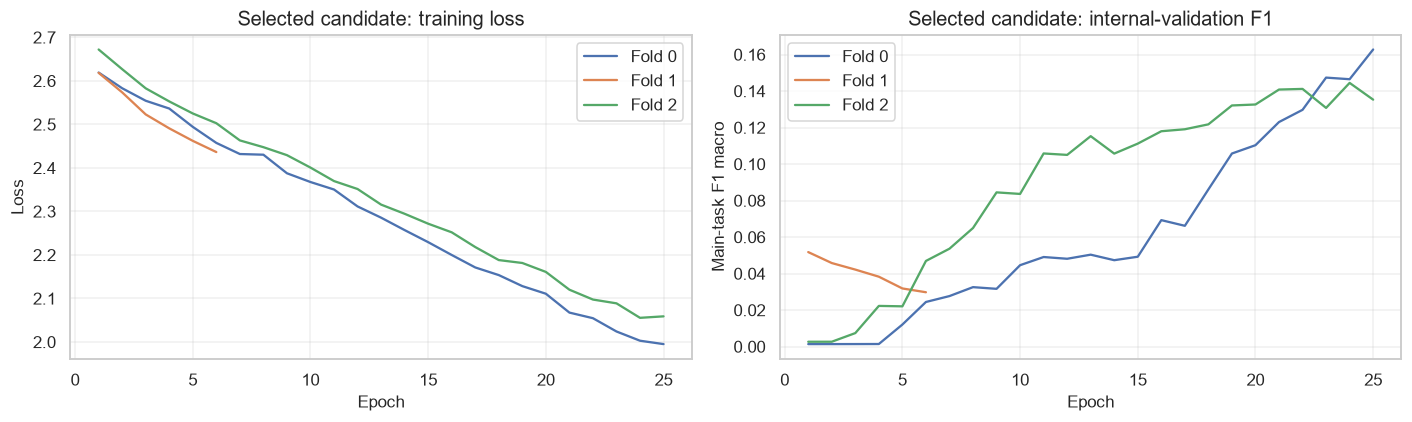

Review before final training: some best epochs are near the search budget limit.


,fold,best_epoch,epochs_run,main_f1_macro
6,0,25,25,0.1628
8,2,24,25,0.1445


In [34]:
# =============================================================================
# FINAL MODEL 2: LEARNING CURVE REVIEW
# =============================================================================

selected_history = training_history.loc[
    training_history["qubits"].eq(BEST_N_QUBITS)
].copy()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for fold, history in selected_history.groupby("fold"):
    history = history.sort_values("epoch")

    axes[0].plot(
        history["epoch"],
        history["training_loss"],
        label=f"Fold {fold}",
    )

    axes[1].plot(
        history["epoch"],
        history["main_f1_macro"],
        label=f"Fold {fold}",
    )

axes[0].set(
    title="Selected candidate: training loss",
    xlabel="Epoch",
    ylabel="Loss",
)

axes[1].set(
    title="Selected candidate: internal-validation F1",
    xlabel="Epoch",
    ylabel="Main-task F1 macro",
)

for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

near_budget_limit = selected_runs.loc[
    selected_runs["best_epoch"]
    >= SEARCH_CONFIG["max_epochs"] - 1
]

if not near_budget_limit.empty:
    print(
        "Review before final training: some best epochs are near "
        "the search budget limit."
    )
    display(near_budget_limit[[
        "fold", "best_epoch", "epochs_run", "main_f1_macro"
    ]])
else:
    print("No selected best epoch is within the last two search epochs.")

In [36]:
# =============================================================================
# FINAL MODEL 3: FREEZE THE TRAINING CONFIGURATION
# =============================================================================
import math
FINAL_EPOCHS = max(
    1,
    int(math.ceil(selected_runs["best_epoch"].median())),
)

FINAL_CONFIG = copy.deepcopy(SEARCH_CONFIG)
FINAL_CONFIG.update({
    "selected_qubits": BEST_N_QUBITS,
    "final_epochs": FINAL_EPOCHS,
    "final_seed": int(SEARCH_CONFIG["seed"]),
    "main_target": MAIN_TARGET,
    "aux_target": AUX_TARGET,
    "main_classes": main_encoder.classes_.tolist(),
    "aux_classes": aux_encoder.classes_.tolist(),
    "feature_columns": list(FEATURE_COLUMNS),
    "numeric_columns": list(MODEL_NUMERIC_COLUMNS),
    "categorical_columns": list(MODEL_CATEGORICAL_COLUMNS),
    "hierarchy_matrix": hierarchy_matrix_np.tolist(),
    "selection_metric": "mean internal-validation main F1 macro",
    "epoch_rule": "ceiling of median selected-candidate best epoch",
    "device": str(device),
})

run_name = datetime.now().strftime("final_qnn_%Y%m%d_%H%M%S_%f")

FINAL_RUN_DIR = Path("outputs") / run_name
FINAL_RUN_DIR.mkdir(parents=True, exist_ok=False)

with (FINAL_RUN_DIR / "final_config.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump(FINAL_CONFIG, file, indent=2, ensure_ascii=False)

search_results.to_csv(
    FINAL_RUN_DIR / "qubit_search_results.csv", index=False
)
training_history.to_csv(
    FINAL_RUN_DIR / "qubit_search_history.csv", index=False
)
final_search_summary.to_csv(
    FINAL_RUN_DIR / "qubit_search_summary.csv", index=False
)

print("Final qubits:", FINAL_CONFIG["selected_qubits"])
print("Final epochs:", FINAL_CONFIG["final_epochs"])
print("Final seed:", FINAL_CONFIG["final_seed"])
print("Output directory:", FINAL_RUN_DIR)

Final qubits: 6
Final epochs: 24
Final seed: 42
Output directory: outputs\final_qnn_20261011_163029_714403


In [40]:
# =============================================================================
# FINAL MODEL 4: FIT PREPROCESSING ON ALL DEVELOPMENT PATIENTS
# =============================================================================

assert len(X_dev) == len(y_main_dev) == len(y_aux_dev)
assert not (
    set(development_data[PATIENT_ID])
    & set(holdout_data[PATIENT_ID])
)

# Usamos 0.95 para que el PCA determine dinámicamente los componentes necesarios
final_preprocessor = build_multitask_preprocessor(
    n_components=0.95
)

X_final_train = np.ascontiguousarray(
    final_preprocessor.fit_transform(X_dev),
    dtype=np.float32,
)

if not np.isfinite(X_final_train).all():
    raise ValueError("Non-finite development features after preprocessing.")

FINAL_INPUT_DIM = X_final_train.shape[1]

# Registramos dinámicamente el número de componentes resultante en la configuración
FINAL_CONFIG["pca_components"] = FINAL_INPUT_DIM

final_main_weights, final_main_counts = balanced_task_weights(
    y_main_dev, N_MAIN_CLASSES
)
final_aux_weights, final_aux_counts = balanced_task_weights(
    y_aux_dev, N_AUX_CLASSES
)

FINAL_CONFIG["input_dim"] = FINAL_INPUT_DIM
FINAL_CONFIG["main_class_weights"] = final_main_weights.tolist()
FINAL_CONFIG["aux_class_weights"] = final_aux_weights.tolist()

display(pd.DataFrame({
    "subclass": main_encoder.classes_,
    "development_count": final_main_counts,
    "loss_weight": final_main_weights,
}).round(3))

display(pd.DataFrame({
    "category": aux_encoder.classes_,
    "development_count": final_aux_counts,
    "loss_weight": final_aux_weights,
}).round(3))

print("Final training matrix:", X_final_train.shape)
print(
    "PCA explained variance:",
    f"{final_preprocessor.named_steps['pca'].explained_variance_ratio_.sum():.2%}",
)
print(f"PCA components selected dynamically: {FINAL_INPUT_DIM}")

# Persist all transformations and label definitions.
joblib.dump(
    {
        "preprocessor": final_preprocessor,
        "main_encoder": main_encoder,
        "aux_encoder": aux_encoder,
        "feature_columns": FEATURE_COLUMNS,
        "hierarchy_matrix": hierarchy_matrix_np,
    },
    FINAL_RUN_DIR / "preprocessing_bundle.joblib",
)

with (FINAL_RUN_DIR / "final_config.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump(FINAL_CONFIG, file, indent=2, ensure_ascii=False)

,subclass,development_count,loss_weight
0,Alzheimer's,122,14.510
1,Cancer,78,22.695
2,Cystic fibrosis,2758,0.642
3,Diabetes,1454,1.217
4,Hemochromatosis,1084,1.633
5,Leber's hereditary optic neuropathy,518,3.417
6,Leigh syndrome,4128,0.429
7,Mitochondrial myopathy,3524,0.502
8,Tay-Sachs,2266,0.781


,category,development_count,loss_weight
0,Mitochondrial genetic inheritance disorders,8356,0.652
1,Multifactorial genetic inheritance disorders,1699,3.206
2,Single-gene inheritance diseases,6284,0.867


Final training matrix: (17822, 45)
PCA explained variance: 95.61%
PCA components selected dynamically: 45


In [41]:
# =============================================================================
# FINAL MODEL 5: INITIALIZE A NEW MODEL
# =============================================================================

initialize_seed(FINAL_CONFIG["final_seed"])

final_dataset = TensorDataset(
    torch.from_numpy(X_final_train),
    torch.from_numpy(y_main_dev),
    torch.from_numpy(y_aux_dev),
    torch.from_numpy(main_mask_dev),
    torch.from_numpy(aux_mask_dev),
)

final_generator = torch.Generator()
final_generator.manual_seed(FINAL_CONFIG["final_seed"])

final_train_loader = DataLoader(
    final_dataset,
    batch_size=FINAL_CONFIG["batch_size"],
    shuffle=True,
    generator=final_generator,
    num_workers=0,
    pin_memory=False,
    drop_last=False,
)

final_model = MultitaskHybridQNN(
    input_dim=FINAL_INPUT_DIM,
    n_qubits=FINAL_CONFIG["selected_qubits"],
    n_layers=FINAL_CONFIG["circuit_layers"],
    hidden_width=FINAL_CONFIG["hidden_width"],
    seed=FINAL_CONFIG["final_seed"],
).to(device)

final_criterion = MultitaskLoss(
    main_weights=final_main_weights,
    aux_weights=final_aux_weights,
    hierarchy=hierarchy_matrix_np,
    aux_coefficient=FINAL_CONFIG["aux_loss_weight"],
    consistency_coefficient=FINAL_CONFIG["consistency_loss_weight"],
).to(device)

final_optimizer = torch.optim.AdamW(
    final_model.parameters(),
    lr=FINAL_CONFIG["learning_rate"],
    weight_decay=FINAL_CONFIG["weight_decay"],
)

print("Device:", device)
print("Development patients:", len(final_dataset))
print("Training batches per epoch:", len(final_train_loader))
print("Final epochs:", FINAL_CONFIG["final_epochs"])
print(
    "Trainable parameters:",
    sum(p.numel() for p in final_model.parameters() if p.requires_grad),
)

Device: cpu
Development patients: 17822
Training batches per epoch: 279
Final epochs: 24
Trainable parameters: 1778


In [ ]:
# =============================================================================
# FINAL MODEL 6: FIXED-EPOCH TRAINING ON ALL DEVELOPMENT DATA
# =============================================================================

final_history_rows = []
final_start_time = time.perf_counter()

for epoch in range(1, FINAL_CONFIG["final_epochs"] + 1):
    final_model.train()

    accumulated_loss = 0.0
    patients_seen = 0
    epoch_start = time.perf_counter()

    progress = tqdm(
        final_train_loader,
        desc=f"Final training | epoch {epoch}",
        leave=False,
    )

    for batch in progress:
        X, y_main, y_aux, main_mask, aux_mask = [
            tensor.to(device) for tensor in batch
        ]

        final_optimizer.zero_grad(set_to_none=True)

        main_logits, aux_logits = final_model(X)

        loss = final_criterion(
            main_logits,
            aux_logits,
            y_main,
            y_aux,
            main_mask,
            aux_mask,
        )

        if not torch.isfinite(loss):
            raise RuntimeError(
                f"Non-finite loss at final epoch {epoch}."
            )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            final_model.parameters(),
            max_norm=1.0,
            error_if_nonfinite=True,
        )

        final_optimizer.step()

        accumulated_loss += loss.item() * len(X)
        patients_seen += len(X)

    epoch_record = {
        "epoch": epoch,
        "training_loss": accumulated_loss / patients_seen,
        "seconds": time.perf_counter() - epoch_start,
    }
    final_history_rows.append(epoch_record)

    # Recovery checkpoint; not selected using holdout results.
    torch.save(
        {
            "epoch": epoch,
            "model_state_dict": final_model.state_dict(),
            "optimizer_state_dict": final_optimizer.state_dict(),
            "config": FINAL_CONFIG,
            "loader_generator_state": final_generator.get_state(),
            "torch_rng_state": torch.get_rng_state(),
        },
        FINAL_RUN_DIR / "latest_training_checkpoint.pt",
    )

    pd.DataFrame(final_history_rows).to_csv(
        FINAL_RUN_DIR / "final_training_history.csv",
        index=False,
    )

    print(
        f"Epoch {epoch:02d}/{FINAL_CONFIG['final_epochs']} | "
        f"loss={epoch_record['training_loss']:.4f} | "
        f"time={epoch_record['seconds'] / 60:.1f} min",
        flush=True,
    )

FINAL_TRAINING_SECONDS = time.perf_counter() - final_start_time
final_training_history = pd.DataFrame(final_history_rows)

# Inference checkpoint.
torch.save(
    {
        "model_state_dict": final_model.state_dict(),
        "config": FINAL_CONFIG,
        "training_seconds": FINAL_TRAINING_SECONDS,
    },
    FINAL_RUN_DIR / "final_model.pt",
)

final_training_history.plot(
    x="epoch",
    y="training_loss",
    marker="o",
    legend=False,
    figsize=(8, 4),
)
plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("Final model: development training")
plt.tight_layout()
plt.show()

print("Final training completed.")
print(f"Total time: {FINAL_TRAINING_SECONDS / 60:.1f} minutes")